# Traffic Sign Detection using Hough Transform and RANSAC

In this notebook, I study a traffic sign detection pipeline for circular signs. I first analyse Canny edge detection parameters, then implement circular sign detection using the Hough Transform and RANSAC from scratch. Finally, I compare both methods quantitatively, extend them to a multi-scale setting with IoU-based NMS, and analyse representative failure cases.

## Notebook Structure

**Setup**
- Importing libraries, loading the dataset, parsing ground-truth annotations, and defining shared helper functions.

**Edge Detection**
- Canny parameter study with at least 10 edge-map visualisations

**Shape Detection**
- Hough circle transform implemented from scratch
- RANSAC circle fitting implemented from scratch

**Quantitative Evaluation**
- Final Canny parameter choices linked to F1-score
- IoU, Precision, Recall, F1-score, PR curves, and runtime comparison

**Multi-Scale Detection**
- Multi-scale detection with IoU-based NMS

**Failure Analysis and Discussions**
- Failure case visualisations and discussion

# 1. Setup

The assignment uses a simplified subset of the German Traffic Sign Detection Benchmark (GTSDB). The dataset is organised with `.ppm` images plus a `gt.txt` annotation file, and the task here is restricted to **circular** traffic signs. This setup section loads the dataset, parses the ground-truth annotations, and defines the shared utilities used throughout the notebook.

## Importing Libraries and Settings

In [1]:
import os
import glob
import math
import time
import random
import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.ndimage import maximum_filter

In [2]:
plt.rcParams["figure.figsize"] = (8, 6)
plt.rcParams["figure.dpi"] = 110
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

## Data Loading and Overview
The cells below load the dataset and filter the annotations so that only circular traffic signs are evaluated. In
the current subset there are **50 images**, **108 total annotations**, and **68 circular annotations**, which is the target
set for all detector metrics reported later in the notebook.


In [3]:
DATASET_DIR = "Dataset_simplified"
IMAGES_DIR = os.path.join(DATASET_DIR, "images")
GT_PATH = os.path.join(DATASET_DIR, "gt.txt")

CIRCULAR_CLASS_IDS = { # Circular sign filter
    0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
    15, 16, 17,
    32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42,
}

gt_columns = ["image_name", "x_min", "y_min", "x_max", "y_max", "class_id"]
gt_df = pd.read_csv(GT_PATH, sep=";", header=None, names=gt_columns)

circular_annotations = gt_df['class_id'].isin(CIRCULAR_CLASS_IDS).sum()

image_paths = sorted(glob.glob(os.path.join(IMAGES_DIR, "*.ppm")))
image_names = [os.path.basename(path) for path in image_paths]

SUBSET_SIZE = 10
subset_image_names = image_names[:SUBSET_SIZE] # Subset for final Canny parameter selection

print(f"Dataset images: {len(image_names)}")
print(f"Total annotations: {len(gt_df)}")
print(f"Total circular annotations: {circular_annotations}")

Dataset images: 50
Total annotations: 108
Total circular annotations: 68


## Shared Functions
These helper functions handle image loading, class filtering, ground-truth drawing, and compact visualisation utilities. They
are reused in the edge-study, detector evaluation, and failure-analysis sections.

In [4]:
# Reads an image from disk using its name and converts it from BGR to RGB format
def read_rgb(image_name):
    image_path = os.path.join(IMAGES_DIR, image_name)
    image_bgr = cv.imread(image_path)
    if image_bgr is None:
        raise FileNotFoundError(image_path)
    return cv.cvtColor(image_bgr, cv.COLOR_BGR2RGB)

# Retrieves ground truth rows for a given image (filters only circular classes)
def get_image_gt(image_name, circular_only=False):
    rows = gt_df[gt_df["image_name"] == image_name].copy()
    if circular_only:
        rows = rows[rows["class_id"].isin(CIRCULAR_CLASS_IDS)].copy()
    return rows.reset_index(drop=True)

# Converts a ground truth row into a bounding box tuple (x_min, y_min, x_max, y_max)
def gt_row_to_box(row):
    return (
        float(row["x_min"]),
        float(row["y_min"]),
        float(row["x_max"]),
        float(row["y_max"]),
    )

# Converts a bounding box into a circle representation (center x, center y, radius)
def bbox_to_circle(row):
    xc = (row["x_min"] + row["x_max"]) / 2.0
    yc = (row["y_min"] + row["y_max"]) / 2.0
    r = min(row["x_max"] - row["x_min"], row["y_max"] - row["y_min"]) / 2.0
    return (float(xc), float(yc), float(r))

# Draws ground truth bounding boxes and class IDs on the image
def draw_ground_truth(image_rgb, image_name, circular_only=True):
    vis = image_rgb.copy()
    rows = get_image_gt(image_name, circular_only=circular_only)
    for _, row in rows.iterrows():
        x1, y1, x2, y2 = map(int, [row.x_min, row.y_min, row.x_max, row.y_max])
        cv.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv.putText(
            vis,
            f"id={int(row.class_id)}",
            (x1, max(16, y1 - 5)),
            cv.FONT_HERSHEY_SIMPLEX,
            0.45,
            (0, 255, 0),
            1,
            cv.LINE_AA,
        )
    return vis
# Computes Intersection over Union (IoU) between two circles using pixel-wise approximation
def circle_iou(c1, c2):
    x1, y1, r1 = c1
    x2, y2, r2 = c2
    x_min = int(math.floor(min(x1 - r1, x2 - r2)))
    y_min = int(math.floor(min(y1 - r1, y2 - r2)))
    x_max = int(math.ceil(max(x1 + r1, x2 + r2)))
    y_max = int(math.ceil(max(y1 + r1, y2 + r2)))
    if x_max <= x_min or y_max <= y_min:
        return 0.0

    yy, xx = np.ogrid[y_min:y_max + 1, x_min:x_max + 1]
    m1 = (xx - x1) ** 2 + (yy - y1) ** 2 <= r1 ** 2
    m2 = (xx - x2) ** 2 + (yy - y2) ** 2 <= r2 ** 2

    inter = np.logical_and(m1, m2).sum()
    union = np.logical_or(m1, m2).sum()
    return float(inter / union) if union > 0 else 0.0

# Overlay circular ground-truth annotations and predicted circles on the same image for detection results.
def overlay_gt_and_predictions(image_rgb, image_name, circles, pred_color=(255, 0, 0), title=""):
    vis = draw_ground_truth(image_rgb, image_name, circular_only=True)
    for xc, yc, radius, score in circles:
        center = (int(round(xc)), int(round(yc)))
        radius = int(round(radius))
        cv.circle(vis, center, radius, pred_color, 2)
    plt.figure(figsize=(10, 7))
    plt.imshow(vis)
    plt.title(title)
    plt.axis("off")
    plt.show()

## Sample Images
Before tuning the detector, it is useful to inspect representative dataset samples together with their ground-truth annotations. This gives visual context for the main challenges in the assignment: scale variation, background clutter, multiple signs per image, and weak or partially occluded sign boundaries.

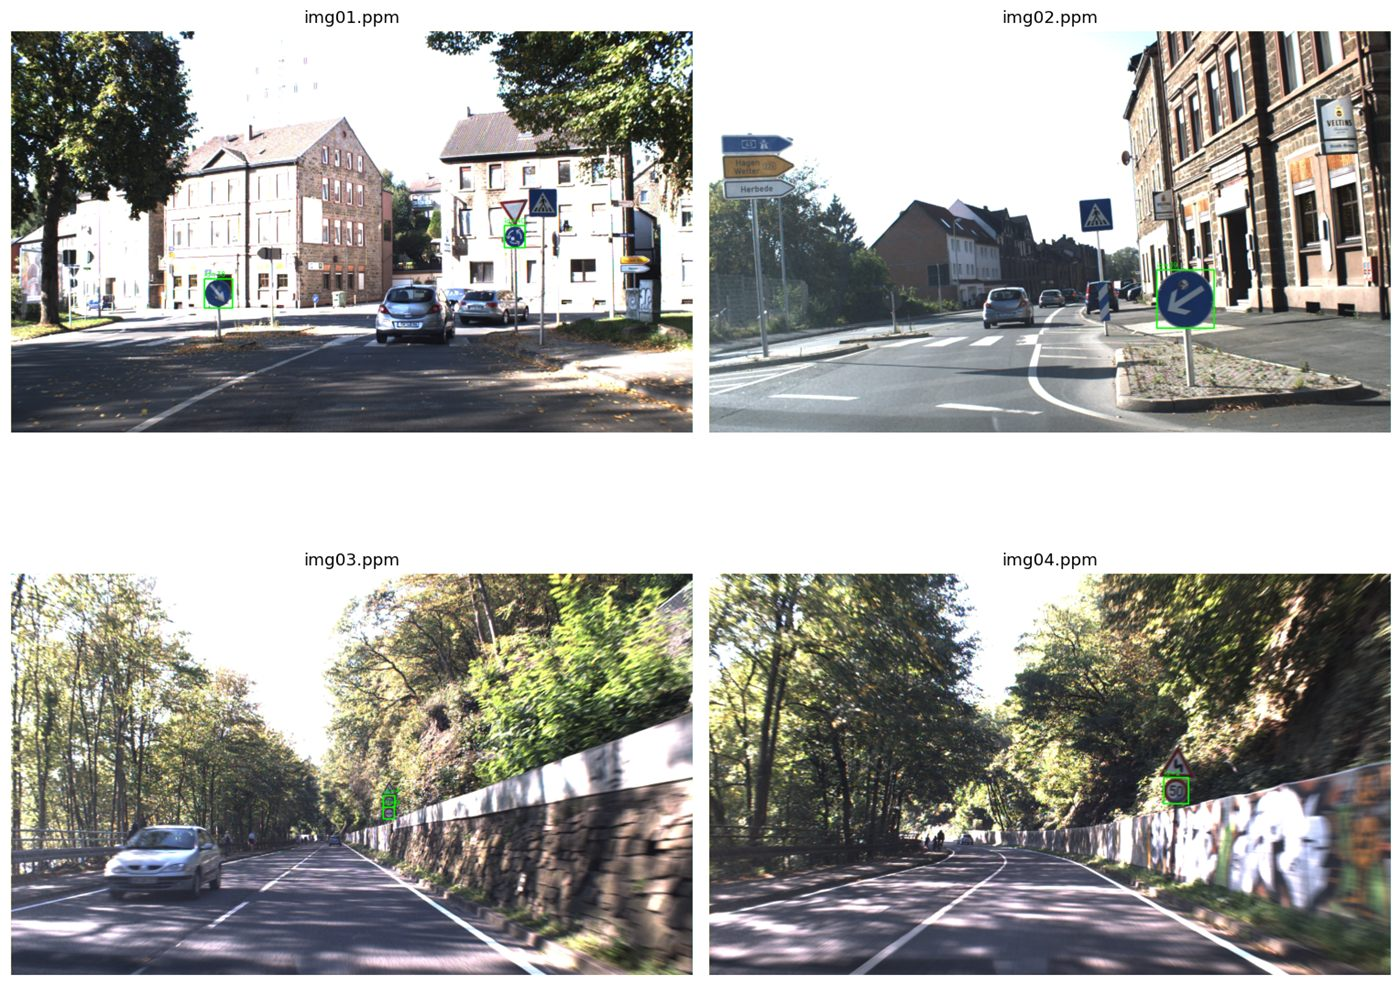

In [5]:
# Displays multiple images with their ground truth annotations in a gallery layout
def show_gt_gallery(image_name_list, circular_only=True, ncols=2, figsize=(14, 12)):
    n = len(image_name_list)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.array(axes).reshape(-1)
    for ax, image_name in zip(axes, image_name_list):
        image_rgb = read_rgb(image_name)
        ax.imshow(draw_ground_truth(image_rgb, image_name, circular_only=circular_only))
        ax.set_title(image_name)
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
show_gt_gallery(subset_image_names[:4], circular_only=True)

# 2. Edge Detection

The Canny edge detector is a multi-stage pipeline:

1. **Gaussian smoothing** reduces noise before computing derivatives.
2. **Gradient magnitude and direction** estimate where intensity changes are strongest.
3. **Non-maximum suppression** thins wide edge responses into one-pixel curves.
4. **Hysteresis thresholding** keeps strong edges and links weak edges only if they connect to strong ones.

In practice:
- Raising the **low threshold** suppresses weak edges and reduces clutter, but may break faint sign boundaries.
- Raising the **high threshold** makes edge acceptance stricter and usually reduces noisy detections.
- Increasing the **Gaussian blur kernel size** can improve edge continuity on noisy backgrounds, but too much blur removes small signs.


In [6]:
# Applies Canny edge detection to an RGB image with optional Gaussian blur preprocessing
def apply_canny(image_rgb, low, high, blur):
    gray = cv.cvtColor(image_rgb, cv.COLOR_RGB2GRAY)
    blur = max(1, int(blur))
    if blur % 2 == 0:
        blur += 1
    blurred = cv.GaussianBlur(gray, (blur, blur), 0)
    edges = cv.Canny(blurred, low, high)
    return edges

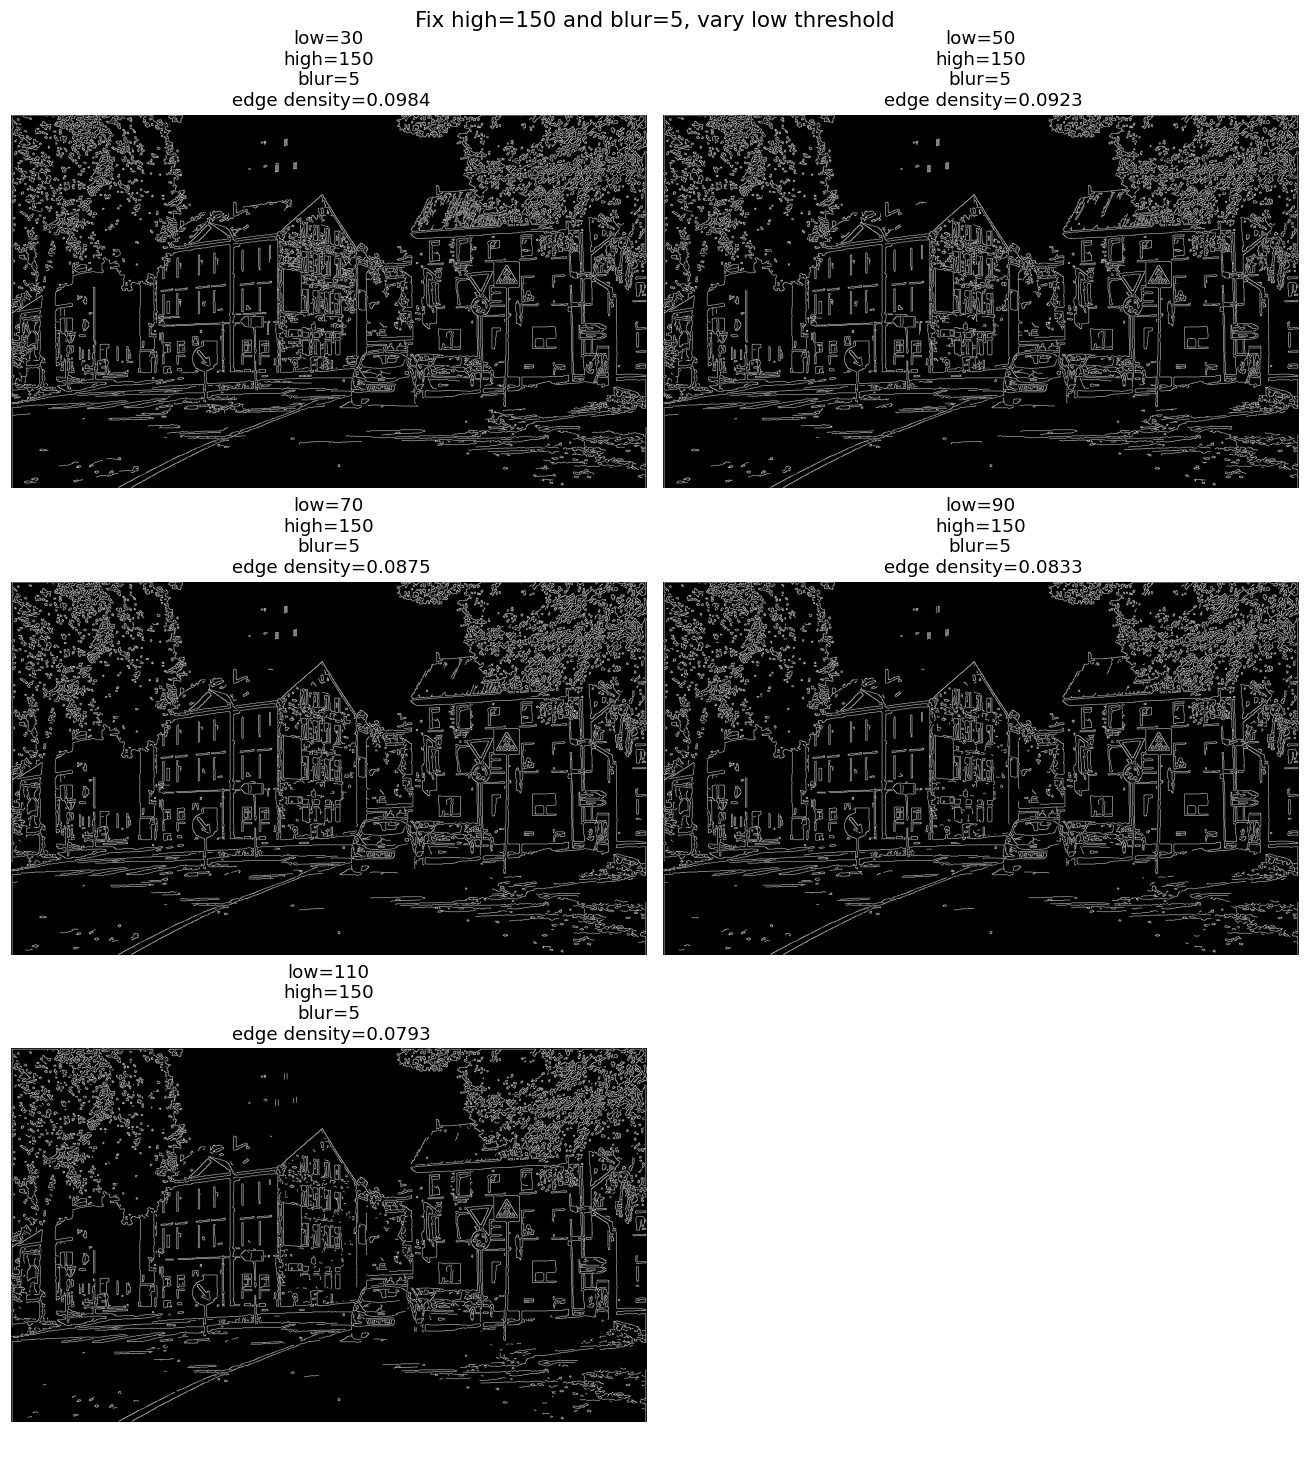

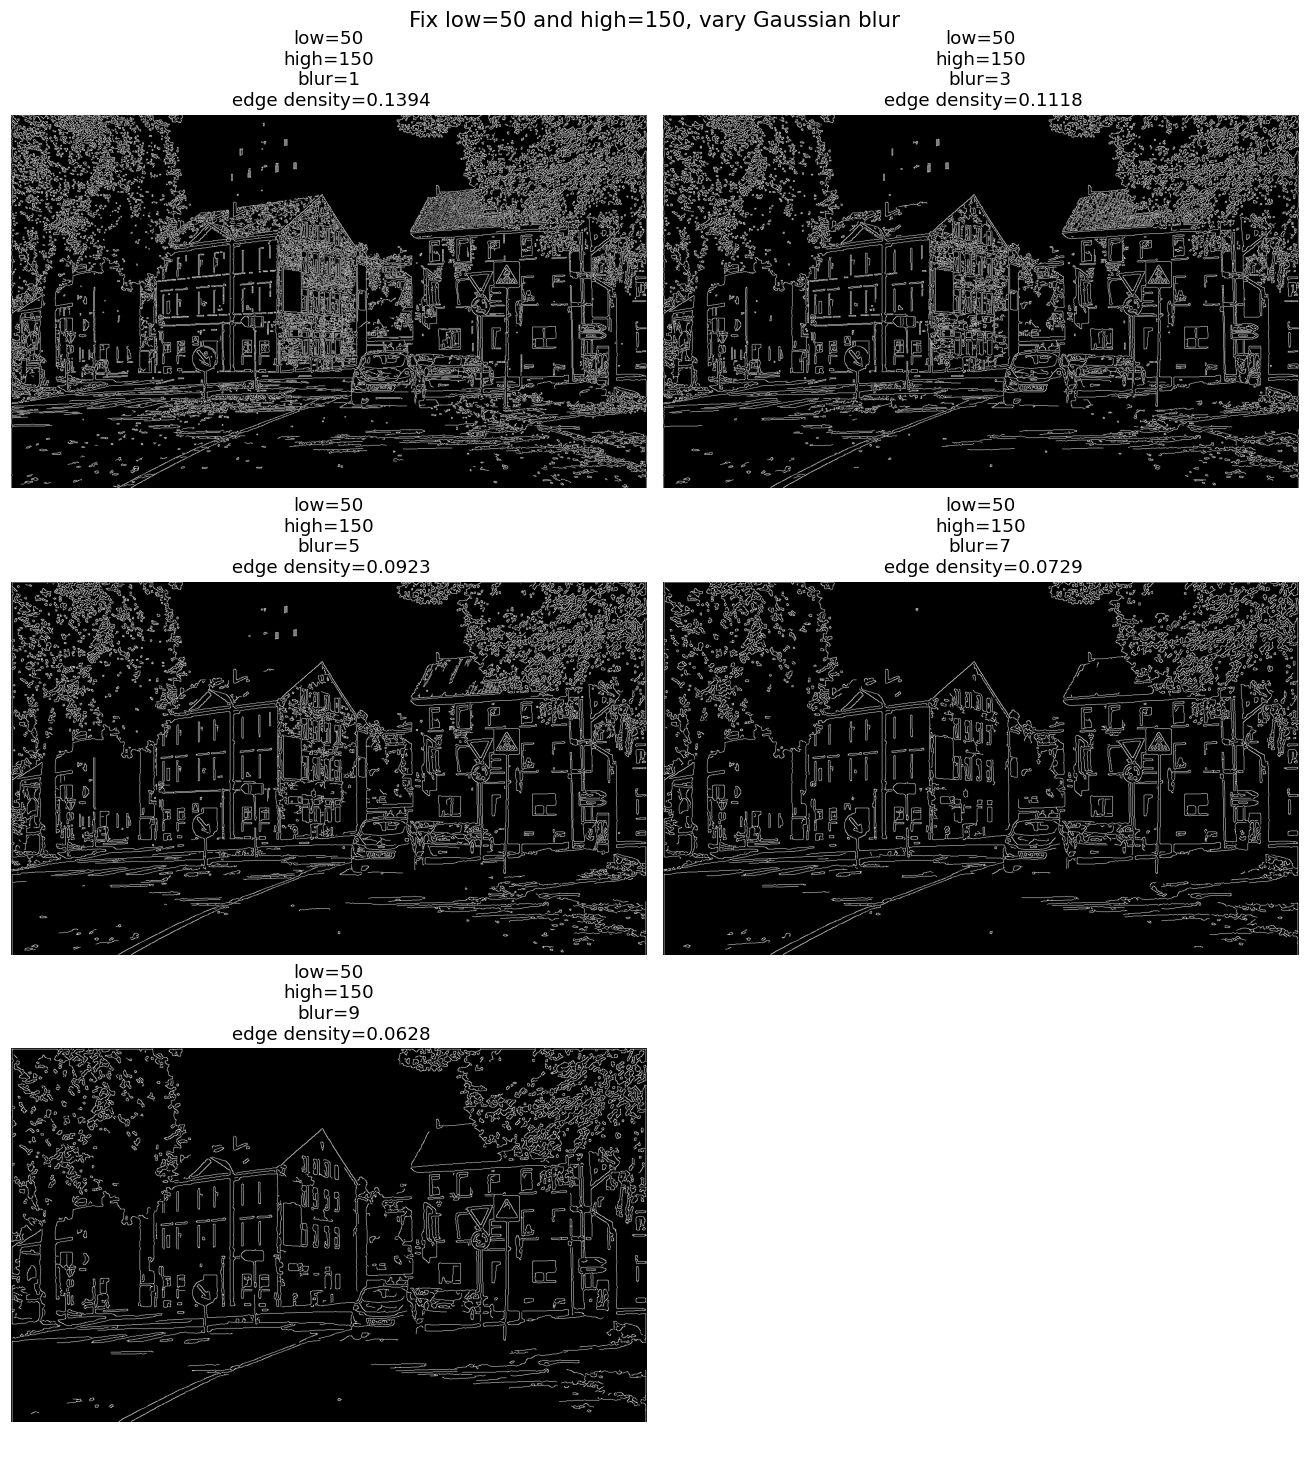

In [7]:
sample_image_name = subset_image_names[0]
sample_image = read_rgb(sample_image_name)

# 10 edge map configuration
low_sweep_configs = [
    {"low": low, "high": 150, "blur": 5}
    for low in [30, 50, 70, 90, 110]
]

blur_sweep_configs = [
    {"low": 50, "high": 150, "blur": blur}
    for blur in [1, 3, 5, 7, 9]
]

# 10 edge map visualisations
def plot_canny_grid(image_rgb, configs, title):
    n = len(configs)
    ncols = 2
    nrows = math.ceil(n / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4.5 * nrows))
    axes = np.array(axes).reshape(-1)

    for i, cfg in enumerate(configs):
        edges = apply_canny(image_rgb, cfg["low"], cfg["high"], cfg["blur"])
        density = float(np.count_nonzero(edges)) / edges.size
        axes[i].imshow(edges, cmap="gray")
        axes[i].set_title(
            f"low={cfg['low']}\nhigh={cfg['high']}\nblur={cfg['blur']}\n edge density={density:.4f}"
        )
        axes[i].axis("off")

    for j in range(i + 1, len(axes)):
        axes[j].axis("off")

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

plot_canny_grid(sample_image, low_sweep_configs, "Fix high=150 and blur=5, vary low threshold")
plot_canny_grid(sample_image, blur_sweep_configs, "Fix low=50 and high=150, vary Gaussian blur")

## Edge-Map Discussion

* Low-threshold sweep shows the expected visual trade-off between preserving weak contours and suppressing background clutter. At lower values such as low = 30, the edge map retains more faint contour fragments, including weak boundaries around small scene elements. This can help preserve subtle circular sign outlines, but it also introduces more clutter from textured regions such as trees, building façades, and road surface details. As the low threshold increases toward 50, 70, 90, and 110, the edge maps become progressively cleaner. However, some weak or incomplete circular boundaries also become less visible, and parts of the traffic sign contours begin to fragment.
* Compared with the low-threshold sweep, the Gaussian blur sweep produces a more noticeable visual change in the edge maps. With very small blur (blur = 1), a large amount of fine background texture remains visible, especially in foliage and other highly textured regions. This results in a cluttered edge map with many small, irrelevant edge fragments. Increasing the blur to 3 clearly reduces this background noise while still preserving the main structural contours in the scene, including the boundaries of the traffic signs. With blur = 5, the edge map becomes cleaner still, but some fine contour detail begins to weaken. For larger blur values such as 7 and 9, the edge maps are visually much smoother and less cluttered, yet some small or weak sign boundaries also become oversmoothed and less distinct.
* Overall, the visual results suggest that **Canny(50, 150)** with a Gaussian blur kernel size of **3** is the strongest candidate for the final pipeline. This setting appears to preserve circular sign boundaries while suppressing unnecessary background clutter. However, the final choice is confirmed later in Section 4 using detector-level **F1-scores** on the 10-image subset rather than visual inspection alone.
* For the remainder of the assignment, I therefore use Canny(50, 150) together with a Gaussian blur kernel size of 3. Visually, this setting gives a good compromise between preserving circular sign boundaries and suppressing unnecessary background edges, making it a reasonable choice for the subsequent circle detection stage.


# 3. Shape Detection

This section implements the two  circle detectors.  I present the **Hough Transform** and **RANSAC** implementations together with inline pseudo-code and a qualitative sanity check on a sample image.





### Non-Maximum Suppression

Both detectors may produce multiple candidate circles around the same sign, especially when nearby hypotheses have similar centres and radii. To avoid counting the same object more than once, a shared circle-level suppression step is applied using **center distance**, **radius difference**, and **circle IoU**. This post-processing step keeps only the strongest representative circle before visualisation and evaluation.

In [8]:
def suppress_duplicate_circles(
    circles,
    center_dist_thr=15,
    radius_gap_thr=5,
    iou_thr=0.5,
    max_circles=None,
):
    circles = sorted(circles, key=lambda item: item[3], reverse=True)
    selected = []

    for candidate in circles:
        cx, cy, radius, score = candidate
        duplicate = False

        for chosen in selected:
            sx, sy, sr, _ = chosen
            center_gap = math.hypot(cx - sx, cy - sy)
            radius_gap = abs(radius - sr)
            overlap_iou = circle_iou(candidate[:3], chosen[:3])
            contained = center_gap + min(radius, sr) <= max(radius, sr)

            if (
                (center_gap <= center_dist_thr and radius_gap <= radius_gap_thr)
                or overlap_iou >= iou_thr
                or contained
            ):
                duplicate = True
                break

        if not duplicate:
            selected.append(candidate)
            if max_circles is not None and len(selected) >= max_circles:
                break

    return selected

### Hough Transform

The Hough Transform detects circles by accumulating votes in a 3D parameter space \(x_c, y_c, r\). Using gradient information reduces the search space by constraining possible circle centers along the normal direction of edge points.

**Input:**
- Edge points
- Grayscale image
- Radius interval \(rmin, rmax\)

**Output:**
- Circle detections \(x_c, y_c, r, score\)

**Pseudo-code:**
1. Create a 3D accumulator \(A(y_c, x_c, r)\).
2. Compute image gradients from the grayscale image.
3. For each edge point:
   - Obtain the local gradient direction.
   - Use this direction as the circle normal.
   - For each radius \(r in rmin, rmax\):
     - Compute the two candidate centers on the normal line.
     - Vote in the accumulator for valid center locations.
4. Select accumulator cells above a threshold as candidate circles.
5. Apply 3D non-maximum suppression over center coordinates and radius.
6. Return the surviving candidates with their vote counts.

**Note:** For efficiency, gradient directions from the grayscale image are used to limit the voting directions of each edge point. This keeps the main Hough formulation unchanged, since the detector still fills a 3-D accumulator over (x_c, y_c, r) and finds circles from its peaks.





In [9]:
def extract_hough_peaks(accumulator, radii, threshold, min_dist=15, max_circles=15):
    # True 3D local-maximum suppression on (yc, xc, r)
    # Spatial window is tied to min_dist, radius window is kept small.
    local_max = maximum_filter(
        accumulator,
        size=(2 * min_dist + 1, 2 * min_dist + 1, 5),
        mode="constant",
    )

    peak_mask = (accumulator == local_max) & (accumulator >= threshold)
    y_idxs, x_idxs, r_idxs = np.nonzero(peak_mask)

    candidates = []
    h, w, _ = accumulator.shape

    for y, x, r_idx in zip(y_idxs, x_idxs, r_idxs):
        radius = int(radii[r_idx])
        votes = int(accumulator[y, x, r_idx])

        candidates.append((int(x), int(y), radius, votes))

    candidates.sort(key=lambda item: item[3], reverse=True)
    return candidates[:max_circles]

The Hough Transform parameters were selected after multiple empirical trials:

- `rmin = 8`, `rmax = 70`: chosen to cover the approximate radius range of circular traffic signs in the dataset.
- `vote_threshold = 0.75`: used to keep only sufficiently strong accumulator peaks.
- `min_votes = 12`: prevents very weak peaks from being accepted as valid circles.
- `min_dist = 15`: suppresses detections whose centres are too close to each other.
- `max_circles = 15`: limits the number of returned detections per image.
- `edge_step = 1`: uses all detected edge points during voting.


In [10]:
# Uses Sobel gradients to restrict centre voting directions for efficiency,
# while still building the full 3-D Hough accumulator over (xc, yc, r).
def hough_circle_transform(
    edge_image,
    gray_image,
    rmin=8,
    rmax=70,
    vote_threshold=0.75,
    min_votes=12,
    min_dist=15,
    max_circles=15,
    edge_step=1,
):
    if edge_image.ndim != 2 or gray_image.ndim != 2:
        raise ValueError("edge_image and gray_image must be 2D.")
    if edge_image.shape != gray_image.shape:
        raise ValueError("edge_image and gray_image must share the same shape.")
    if rmin <= 0 or rmax < rmin:
        raise ValueError("Invalid radius range.")

    height, width = edge_image.shape
    radii = np.arange(rmin, rmax + 1, dtype=np.int32)
    accumulator = np.zeros((height, width, len(radii)), dtype=np.uint16)

    ys, xs = np.nonzero(edge_image)
    ys = ys[::edge_step]
    xs = xs[::edge_step]

    gx = cv.Sobel(gray_image, cv.CV_32F, 1, 0, ksize=3)
    gy = cv.Sobel(gray_image, cv.CV_32F, 0, 1, ksize=3)

    dx = gx[ys, xs]
    dy = gy[ys, xs]
    norms = np.hypot(dx, dy)
    valid = norms > 1e-6
    ys = ys[valid]
    xs = xs[valid]
    nx = dx[valid] / norms[valid]
    ny = dy[valid] / norms[valid]

    for r_idx, radius in enumerate(radii):
        for sign in (1, -1):
            xc = np.rint(xs + sign * radius * nx).astype(np.int32)
            yc = np.rint(ys + sign * radius * ny).astype(np.int32)
            in_bounds = (xc >= 0) & (xc < width) & (yc >= 0) & (yc < height)
            np.add.at(accumulator[:, :, r_idx], (yc[in_bounds], xc[in_bounds]), 1)

    max_vote = int(accumulator.max())
    if max_vote == 0:
        return [], accumulator

    threshold = int(np.ceil(max_vote * vote_threshold)) if vote_threshold < 1 else int(vote_threshold)
    threshold = max(threshold, min_votes)
    circles = extract_hough_peaks(
        accumulator,
        radii=radii,
        threshold=threshold,
        min_dist=min_dist,
        max_circles=max_circles,
    )
    return circles, accumulator

def detect_hough_from_rgb(image_rgb, canny_cfg, hough_cfg):
    gray = cv.cvtColor(image_rgb, cv.COLOR_RGB2GRAY)
    raw_edges = apply_canny(image_rgb, canny_cfg["low"], canny_cfg["high"], canny_cfg["blur"])
    circles, accumulator = hough_circle_transform(
        edge_image=raw_edges,
        gray_image=gray,
        **hough_cfg,
    )

    circles = suppress_duplicate_circles(
        circles,
        center_dist_thr=hough_cfg["min_dist"],
        radius_gap_thr=6,
        iou_thr=0.35,
        max_circles=hough_cfg["max_circles"],
    )

    return raw_edges, circles, accumulator

### RANSAC

RANSAC detects circles by repeatedly sampling minimal point sets and fitting circle models, selecting those supported by a sufficient number of inliers. It is robust to noise and outliers in edge data.

**Input:**
- Edge points
- Number of iterations \(N\)
- Distance threshold \(epsilon\)
- Minimum inlier count

**Output:**
- Circle detections \(x_c, y_c, r, score\)

**Pseudocode:**
1. For \(i = 1 dots N):
   - Randomly sample 3 non-collinear points.
   - Fit a circle \((x_c, y_c, r)\) through the points.
   - Compute distances of all edge points to the circle.
   - Count inliers within threshold \(\epsilon\).
2. Keep circle models whose radius lies in \(rmin, rmax\) and whose inlier count exceeds the minimum threshold.
3. Apply non-maximum suppression to remove duplicate detections.
4. Return the surviving circle candidates as \(x_c, y_c, r, inlier count\) tuples.

In [11]:
def fit_circle_from_3_points(p1, p2, p3):
    x1, y1 = p1
    x2, y2 = p2
    x3, y3 = p3

    temp = x2 ** 2 + y2 ** 2
    bc = (x1 ** 2 + y1 ** 2 - temp) / 2.0
    cd = (temp - x3 ** 2 - y3 ** 2) / 2.0
    det = (x1 - x2) * (y2 - y3) - (x2 - x3) * (y1 - y2)

    if abs(det) < 1e-8:
        return None

    cx = (bc * (y2 - y3) - cd * (y1 - y2)) / det
    cy = ((x1 - x2) * cd - (x2 - x3) * bc) / det
    radius = math.hypot(x1 - cx, y1 - cy)

    if not np.isfinite(cx) or not np.isfinite(cy) or not np.isfinite(radius) or radius <= 0:
        return None

    return (float(cx), float(cy), float(radius))

The RANSAC parameters were determined after several empirical trials. However, RANSAC did not provide sufficiently strong overall performance in this notebook, since it was sensitive to noisy edge maps, produced unstable circle fits, and yielded many false positives while still missing a large portion of the true signs. For this reason, the final parameter values were selected by considering both detection quality and runtime.

- `rmin = 8` and `rmax = 70`: selected according to the expected sign radius range.
- `iterations = 3000`: increased to improve robustness by sampling more candidate circle hypotheses.
- `epsilon = 2.5`: used as a stricter inlier tolerance for circle fitting.
- `min_inliers = 40`: increased to reject weak hypotheses with limited support.
- `max_circles = 10`: reduced to limit excessive detections per image.
- `min_dist = 20`: increased to suppress nearby duplicate detections more aggressively.


In [12]:
def ransac_circle_detection(
    edge_image,
    rmin=8,
    rmax=70,
    iterations=3000,
    epsilon=2.5,
    min_inliers=40,
    max_circles=10,
    min_dist=20,
):
    ys, xs = np.nonzero(edge_image)
    points = np.column_stack([xs, ys]).astype(np.float32)
    if len(points) < 3:
        return []

    rng = np.random.default_rng(SEED)
    candidates = []

    for _ in range(iterations):
        sample_ids = rng.choice(len(points), size=3, replace=False)
        model = fit_circle_from_3_points(points[sample_ids][0], points[sample_ids][1], points[sample_ids][2])
        if model is None:
            continue

        cx, cy, radius = model
        if radius < rmin or radius > rmax:
            continue

        residuals = np.abs(np.hypot(points[:, 0] - cx, points[:, 1] - cy) - radius)
        inlier_count = int((residuals <= epsilon).sum())
        if inlier_count >= min_inliers:
            candidates.append((cx, cy, radius, inlier_count))

    return suppress_duplicate_circles(
        candidates,
        center_dist_thr=min_dist,
        radius_gap_thr=5,
        iou_thr=0.45,
        max_circles=max_circles,
    )


def detect_ransac_from_rgb(image_rgb, canny_cfg, ransac_cfg):
    raw_edges = apply_canny(image_rgb, canny_cfg["low"], canny_cfg["high"], canny_cfg["blur"])
    circles = ransac_circle_detection(
        edge_image=raw_edges,
        **ransac_cfg,
    )
    return raw_edges, circles

### Qualitative Detection Example
The following example presents a qualitative comparison of Hough Transform and RANSAC on a single sample image. Using the detector configurations defined above, both methods are applied after Canny edge extraction, and their predicted circles are overlaid with the circular ground-truth annotations. This example is intended to provide an intuitive visual comparison before moving to the full quantitative evaluation.

In [13]:
default_canny_cfg = { # The reason for Canny parameter's relationship to the F1 score will be explained later.
    "low": 50,
    "high": 150,
    "blur": 3,
}

default_hough_cfg = { # The reason for the parameters was explained earlier.
    "rmin": 8,
    "rmax": 70,
    "vote_threshold": 0.75,
    "min_votes": 12,
    "min_dist": 15,
    "max_circles": 15,
    "edge_step": 1,
}

default_ransac_cfg = { # The reason for the parameters was explained earlier.
    "rmin": 8,
    "rmax": 70,
    "iterations": 3000,
    "epsilon": 2.5,
    "min_inliers": 40,
    "max_circles": 10,
    "min_dist": 20,
}

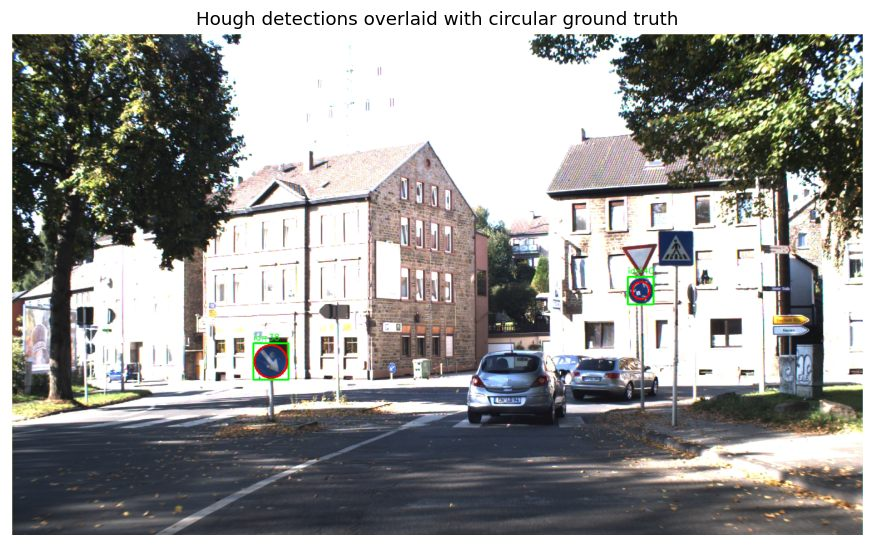

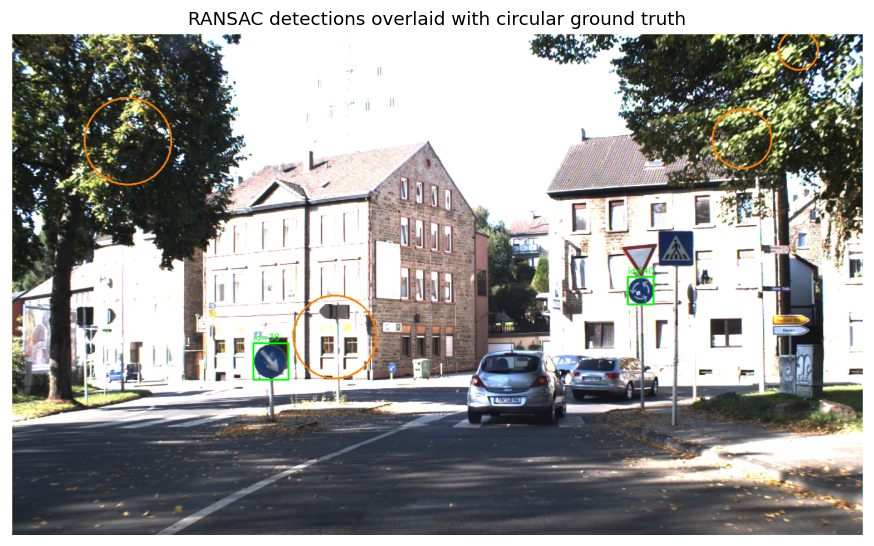

Hough detections: 2
RANSAC detections: 4
Accumulator shape: (800, 1360, 63)


In [14]:
_, hough_sample_circles, sample_accumulator = detect_hough_from_rgb(
    sample_image,
    default_canny_cfg,
    default_hough_cfg,
)

_, ransac_sample_circles = detect_ransac_from_rgb(
    sample_image,
    default_canny_cfg,
    default_ransac_cfg,
)

overlay_gt_and_predictions(
    sample_image,
    sample_image_name,
    hough_sample_circles,
    pred_color=(255, 0, 0),
    title="Hough detections overlaid with circular ground truth",
)

overlay_gt_and_predictions(
    sample_image,
    sample_image_name,
    ransac_sample_circles,
    pred_color=(255, 128, 0),
    title="RANSAC detections overlaid with circular ground truth",
)

print("Hough detections:", len(hough_sample_circles))
print("RANSAC detections:", len(ransac_sample_circles))
print("Accumulator shape:", sample_accumulator.shape)


# 4. Quantitative Evaluation

This section compares the detectors using **IoU-based matching**, **precision**, **recall**, **F1-score**, **PR curves**, and **average runtime**. The Canny study is first linked to detector-level F1, and the resulting scores are then used to determine the final Canny parameter setting before the full-dataset comparison between Hough and RANSAC at **IoU threshold = 0.5**. For efficiency, the Canny parameter study is carried out on a **10-image subset**, while the final detector comparison is performed on the full dataset.

Since this IoU threshold is relatively strict, some detections that appear visually correct may still be counted as false positives if their overlap with the ground-truth annotation remains below **0.5**, which can directly reduce the measured **F1-score**. Therefore, the quantitative results should be interpreted with this stricter matching criterion in mind.

### Evaluation Helpers

The following helper functions define the matching and metric computations used throughout the evaluation stage. They are responsible for IoU calculation, greedy matching between predictions and ground-truth annotations, and the computation of precision, recall, and F1-score.


In [15]:
def circle_box_iou(circle, box):
    xc, yc, r = circle
    x1, y1, x2, y2 = box
    x_min = int(math.floor(min(xc - r, x1)))
    y_min = int(math.floor(min(yc - r, y1)))
    x_max = int(math.ceil(max(xc + r, x2)))
    y_max = int(math.ceil(max(yc + r, y2)))
    if x_max <= x_min or y_max <= y_min:
        return 0.0

    yy, xx = np.ogrid[y_min:y_max + 1, x_min:x_max + 1]
    circle_mask = (xx - xc) ** 2 + (yy - yc) ** 2 <= r ** 2
    box_mask = (xx >= x1) & (xx <= x2) & (yy >= y1) & (yy <= y2)

    inter = np.logical_and(circle_mask, box_mask).sum()
    union = np.logical_or(circle_mask, box_mask).sum()
    return float(inter / union) if union > 0 else 0.0


def compute_prf(tp, fp, fn):
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return precision, recall, f1


def greedy_match_detections(pred_circles, gt_boxes, iou_thr=0.5):
    used_gt = set()
    matches = []
    pred_sorted = sorted(pred_circles, key=lambda item: item[3], reverse=True)

    for pred in pred_sorted:
        best_iou = 0.0
        best_gt_idx = None
        for gt_idx, gt_box in enumerate(gt_boxes):
            if gt_idx in used_gt:
                continue
            iou = circle_box_iou(pred[:3], gt_box)
            if iou > best_iou:
                best_iou = iou
                best_gt_idx = gt_idx
        if best_gt_idx is not None and best_iou >= iou_thr:
            used_gt.add(best_gt_idx)
            matches.append((pred, gt_boxes[best_gt_idx], best_iou))

    tp = len(matches)
    fp = len(pred_circles) - tp
    fn = len(gt_boxes) - tp
    return matches, tp, fp, fn


def score_detections_against_gt(pred_circles, gt_boxes):
    if not pred_circles:
        return []
    scored = []
    for pred in pred_circles:
        best_iou = 0.0
        for gt_box in gt_boxes:
            best_iou = max(best_iou, circle_box_iou(pred[:3], gt_box))
        scored.append(best_iou)
    return scored


### Detector Evaluation Functions

The following functions evaluate the detectors at the dataset level and summarise their outputs both quantitatively and qualitatively. They are used to compute per-image and overall metrics, generate detection galleries, and produce the threshold sweeps required for the precision-recall analysis.

In [16]:
def evaluate_detector_on_images(image_name_list, detector_name, canny_cfg, detector_cfg, iou_thr=0.5):
    total_tp = total_fp = total_fn = 0
    matched_ious = []
    nearest_pred_ious = []
    runtimes = []
    per_image_rows = []
    detections_by_image = {}

    for image_name in image_name_list:
        image_rgb = read_rgb(image_name)
        gt_rows = get_image_gt(image_name, circular_only=True)
        gt_boxes = [gt_row_to_box(row) for _, row in gt_rows.iterrows()]

        t0 = time.perf_counter()
        if detector_name == "hough":
            raw_edges, pred_circles, _ = detect_hough_from_rgb(image_rgb, canny_cfg, detector_cfg)
        elif detector_name == "ransac":
            raw_edges, pred_circles = detect_ransac_from_rgb(image_rgb, canny_cfg, detector_cfg)
        else:
            raise ValueError("detector_name must be 'hough' or 'ransac'.")
        elapsed = time.perf_counter() - t0

        matches, tp, fp, fn = greedy_match_detections(pred_circles, gt_boxes, iou_thr=iou_thr)
        pred_ious = score_detections_against_gt(pred_circles, gt_boxes)

        total_tp += tp
        total_fp += fp
        total_fn += fn
        runtimes.append(elapsed)
        matched_ious.extend([match[2] for match in matches])
        nearest_pred_ious.extend(pred_ious)

        precision, recall, f1 = compute_prf(tp, fp, fn)
        per_image_rows.append(
            {
                "image_name": image_name,
                "num_gt": len(gt_boxes),
                "num_pred": len(pred_circles),
                "tp": tp,
                "fp": fp,
                "fn": fn,
                "precision": precision,
                "recall": recall,
                "f1": f1,
                "mean_best_pred_iou": float(np.mean(pred_ious)) if pred_ious else 0.0,
                "mean_matched_iou": float(np.mean([match[2] for match in matches])) if matches else 0.0,
                "runtime_sec": elapsed,
            }
        )

        detections_by_image[image_name] = {
            "image_rgb": image_rgb,
            "raw_edges": raw_edges,
            "circles": pred_circles,
            "gt_boxes": gt_boxes,
        }

    precision, recall, f1 = compute_prf(total_tp, total_fp, total_fn)
    summary = {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "mean_matched_iou": float(np.mean(matched_ious)) if matched_ious else 0.0,
        "mean_best_pred_iou": float(np.mean(nearest_pred_ious)) if nearest_pred_ious else 0.0,
        "avg_runtime_sec": float(np.mean(runtimes)) if runtimes else 0.0,
        "tp": total_tp,
        "fp": total_fp,
        "fn": total_fn,
    }
    return pd.DataFrame(per_image_rows), summary, detections_by_image


def plot_detection_gallery(detections_by_image, image_name_list, title_prefix, pred_color=(255, 0, 0), ncols=2):
    n = len(image_name_list)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4.8 * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, image_name in zip(axes, image_name_list):
        item = detections_by_image[image_name]
        vis = draw_ground_truth(item["image_rgb"], image_name, circular_only=True)
        for xc, yc, radius, score in item["circles"]:
            cv.circle(vis, (int(round(xc)), int(round(yc))), int(round(radius)), pred_color, 2)
        ax.imshow(vis)
        ax.set_title(f"{title_prefix}: {image_name}")
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


def sweep_thresholds_for_pr(image_name_list, detector_name, canny_cfg, detector_cfg, thresholds, iou_thr=0.5):
    rows = []

    for threshold in thresholds:
        cfg = dict(detector_cfg)
        if detector_name == "hough":
            cfg["min_votes"] = int(threshold)
            cfg["vote_threshold"] = 0.0
        else:
            cfg["min_inliers"] = int(threshold)

        _, summary, _ = evaluate_detector_on_images(
            image_name_list=image_name_list,
            detector_name=detector_name,
            canny_cfg=canny_cfg,
            detector_cfg=cfg,
            iou_thr=iou_thr,
        )
        rows.append(
            {
                "threshold": threshold,
                "precision": summary["precision"],
                "recall": summary["recall"],
                "f1": summary["f1"],
            }
        )

    return pd.DataFrame(rows)


## Final Canny Parameter Selection
The following experiment links the Canny parameter study to detector-level performance. By evaluating different Canny configurations on the 10-image subset, the final parameter setting is selected according to the highest F1-score.

In [17]:
canny_tuning_hough_cfg = {
    "rmin": 8,
    "rmax": 70,
    "vote_threshold": 0.75,
    "min_votes": 12,
    "min_dist": 15,
    "max_circles": 15,
    "edge_step": 1,
}

canny_candidates = low_sweep_configs + blur_sweep_configs
canny_rows = []

for cfg in canny_candidates:
    _, summary, _ = evaluate_detector_on_images(
        image_name_list=subset_image_names,
        detector_name="hough",
        canny_cfg=cfg,
        detector_cfg=canny_tuning_hough_cfg,
        iou_thr=0.5,
    )
    canny_rows.append(
        {
            "low": cfg["low"],
            "high": cfg["high"],
            "blur": cfg["blur"],
            "precision": summary["precision"],
            "recall": summary["recall"],
            "f1": summary["f1"],
            "avg_runtime_sec": summary["avg_runtime_sec"],
        }
    )

canny_results_df = pd.DataFrame(canny_rows).sort_values(
    by=["f1", "precision", "recall"], ascending=False
).reset_index(drop=True)
display(canny_results_df)

best_canny_cfg = {
    "low": int(canny_results_df.iloc[0]["low"]),
    "high": int(canny_results_df.iloc[0]["high"]),
    "blur": int(canny_results_df.iloc[0]["blur"]),
}
print("Selected final Canny parameters:", best_canny_cfg)

,low,high,blur,precision,recall,f1,avg_runtime_sec
0,50,150,3,0.333333,0.363636,0.347826,4.583771
1,50,150,9,0.428571,0.272727,0.333333,3.114886
2,50,150,1,0.272727,0.272727,0.272727,5.446514
3,30,150,5,0.250000,0.272727,0.260870,3.404170
4,50,150,5,0.250000,0.272727,0.260870,3.526514
5,70,150,5,0.250000,0.272727,0.260870,3.861121
6,90,150,5,0.250000,0.272727,0.260870,4.309943
7,110,150,5,0.250000,0.272727,0.260870,3.485761
8,50,150,5,0.250000,0.272727,0.260870,3.912779
9,50,150,7,0.222222,0.181818,0.200000,3.185474


Selected final Canny parameters: {'low': 50, 'high': 150, 'blur': 3}


The table confirms that the visually strongest edge map is not necessarily the best detector input. Within the low-threshold sweep, **low = 50** gives the best detector-level balance, outperforming **30, 70, 90, and 110**, which either retain too much clutter or fragment weak sign boundaries too aggressively. Combined with the blur sweep, the best result on the 10-image subset is obtained with **low = 50**, **high = 150**, and **blur = 3**, achieving **F1 = 0.3478**.

A larger blur value of **9** increases precision to **0.4286**, but its lower recall reduces the overall **F1** to **0.3333**, while **blur = 1** underperforms because noisy background edges remain too strong. Based on both the edge visualisations and the detector-level scores, I use **(low, high, blur) = (50, 150, 3)** as the final Canny configuration.




## Compare Hough and RANSAC

After fixing the Canny parameters, the notebook compares the two shape detectors using IoU, Precision, Recall, F1, PR curves, and runtime.
The quantitative metrics in this subsection are computed on the **full dataset**. The detection galleries below are still shown on the 10-image subset for readability.


In [18]:
comparison_image_names = image_names

hough_per_image_df, hough_summary, hough_detections = evaluate_detector_on_images(
    image_name_list=comparison_image_names,
    detector_name="hough",
    canny_cfg=best_canny_cfg,
    detector_cfg=default_hough_cfg,
    iou_thr=0.5,
)

ransac_per_image_df, ransac_summary, ransac_detections = evaluate_detector_on_images(
    image_name_list=comparison_image_names,
    detector_name="ransac",
    canny_cfg=best_canny_cfg,
    detector_cfg=default_ransac_cfg,
    iou_thr=0.5,
)

comparison_df = pd.DataFrame(
    [
        {"method": "Hough", **hough_summary},
        {"method": "RANSAC", **ransac_summary},
    ]
).sort_values(by="f1", ascending=False)

display(comparison_df)

,method,precision,recall,f1,mean_matched_iou,mean_best_pred_iou,avg_runtime_sec,tp,fp,fn
0,Hough,0.312500,0.294118,0.303030,0.650909,0.338867,3.160042,20,44,48
1,RANSAC,0.004545,0.029412,0.007874,0.698310,0.008158,0.088495,2,438,66


## Summary Discussion

* The comparison table consistently favours **Hough** over **RANSAC** in this notebook. On the full dataset, **Hough** achieves **precision = 0.3125**, **recall = 0.2941**, and **F1 = 0.3030**, whereas **RANSAC** achieves only **precision = 0.0045**, **recall = 0.0294**, and **F1 = 0.0079**. In absolute terms, Hough produces **20 true positives**, while RANSAC produces only **2**.

* **RANSAC** is much faster, averaging **0.0885 s/image**, whereas **Hough** requires **3.1600 s/image**. The runtime trade-off is therefore real; however, this speed advantage does not compensate for the very poor detection quality of the current RANSAC pipeline.

* RANSAC’s **mean matched IoU = 0.6983** is slightly higher than Hough’s **0.6509**, but this value should not be over-interpreted because it is computed from only **two true positives**. In practice, **Hough** is the preferable method in this notebook because it is the only detector that achieves a usable balance between precision and recall.

### Per-Image Results: Hough

In [19]:
display(hough_per_image_df)

,image_name,num_gt,num_pred,tp,fp,fn,precision,recall,f1,mean_best_pred_iou,mean_matched_iou,runtime_sec
0,img01.ppm,2,2,1,1,1,0.500000,0.500000,0.500000,0.477513,0.630687,4.638053
1,img02.ppm,1,1,1,0,0,1.000000,1.000000,1.000000,0.731698,0.731698,3.941668
2,img03.ppm,2,2,0,2,2,0.000000,0.000000,0.000000,0.349449,0.000000,6.508342
3,img04.ppm,1,1,0,1,1,0.000000,0.000000,0.000000,0.380755,0.000000,5.037162
4,img05.ppm,1,1,1,0,0,1.000000,1.000000,1.000000,0.555060,0.555060,3.118293
5,img06.ppm,1,1,1,0,0,1.000000,1.000000,1.000000,0.676653,0.676653,6.564559
6,img07.ppm,1,1,0,1,1,0.000000,0.000000,0.000000,0.398214,0.000000,3.921065
7,img08.ppm,0,1,0,1,0,0.000000,0.000000,0.000000,0.000000,0.000000,2.048664
8,img09.ppm,1,1,0,1,1,0.000000,0.000000,0.000000,0.279598,0.000000,2.799419
9,img10.ppm,1,1,0,1,1,0.000000,0.000000,0.000000,0.000000,0.000000,4.902932


### Per-Image Results: RANSAC

In [20]:
display(ransac_per_image_df)

,image_name,num_gt,num_pred,tp,fp,fn,precision,recall,f1,mean_best_pred_iou,mean_matched_iou,runtime_sec
0,img01.ppm,2,4,0,4,2,0.0,0.00,0.000000,0.000000,0.000000,0.096251
1,img02.ppm,1,10,0,10,1,0.0,0.00,0.000000,0.000797,0.000000,0.107165
2,img03.ppm,2,4,0,4,2,0.0,0.00,0.000000,0.000000,0.000000,0.074372
3,img04.ppm,1,6,0,6,1,0.0,0.00,0.000000,0.000000,0.000000,0.080277
4,img05.ppm,1,9,0,9,1,0.0,0.00,0.000000,0.000000,0.000000,0.108201
5,img06.ppm,1,6,0,6,1,0.0,0.00,0.000000,0.000000,0.000000,0.080188
6,img07.ppm,1,8,0,8,1,0.0,0.00,0.000000,0.000065,0.000000,0.102897
7,img08.ppm,0,10,0,10,0,0.0,0.00,0.000000,0.000000,0.000000,0.074043
8,img09.ppm,1,10,0,10,1,0.0,0.00,0.000000,0.000000,0.000000,0.079030
9,img10.ppm,1,9,0,9,1,0.0,0.00,0.000000,0.000000,0.000000,0.088246


### Detection Gallery: Hough

The following gallery presents **10 example images** and shows how the Hough detector behaves on the subset selected for qualitative visual inspection.


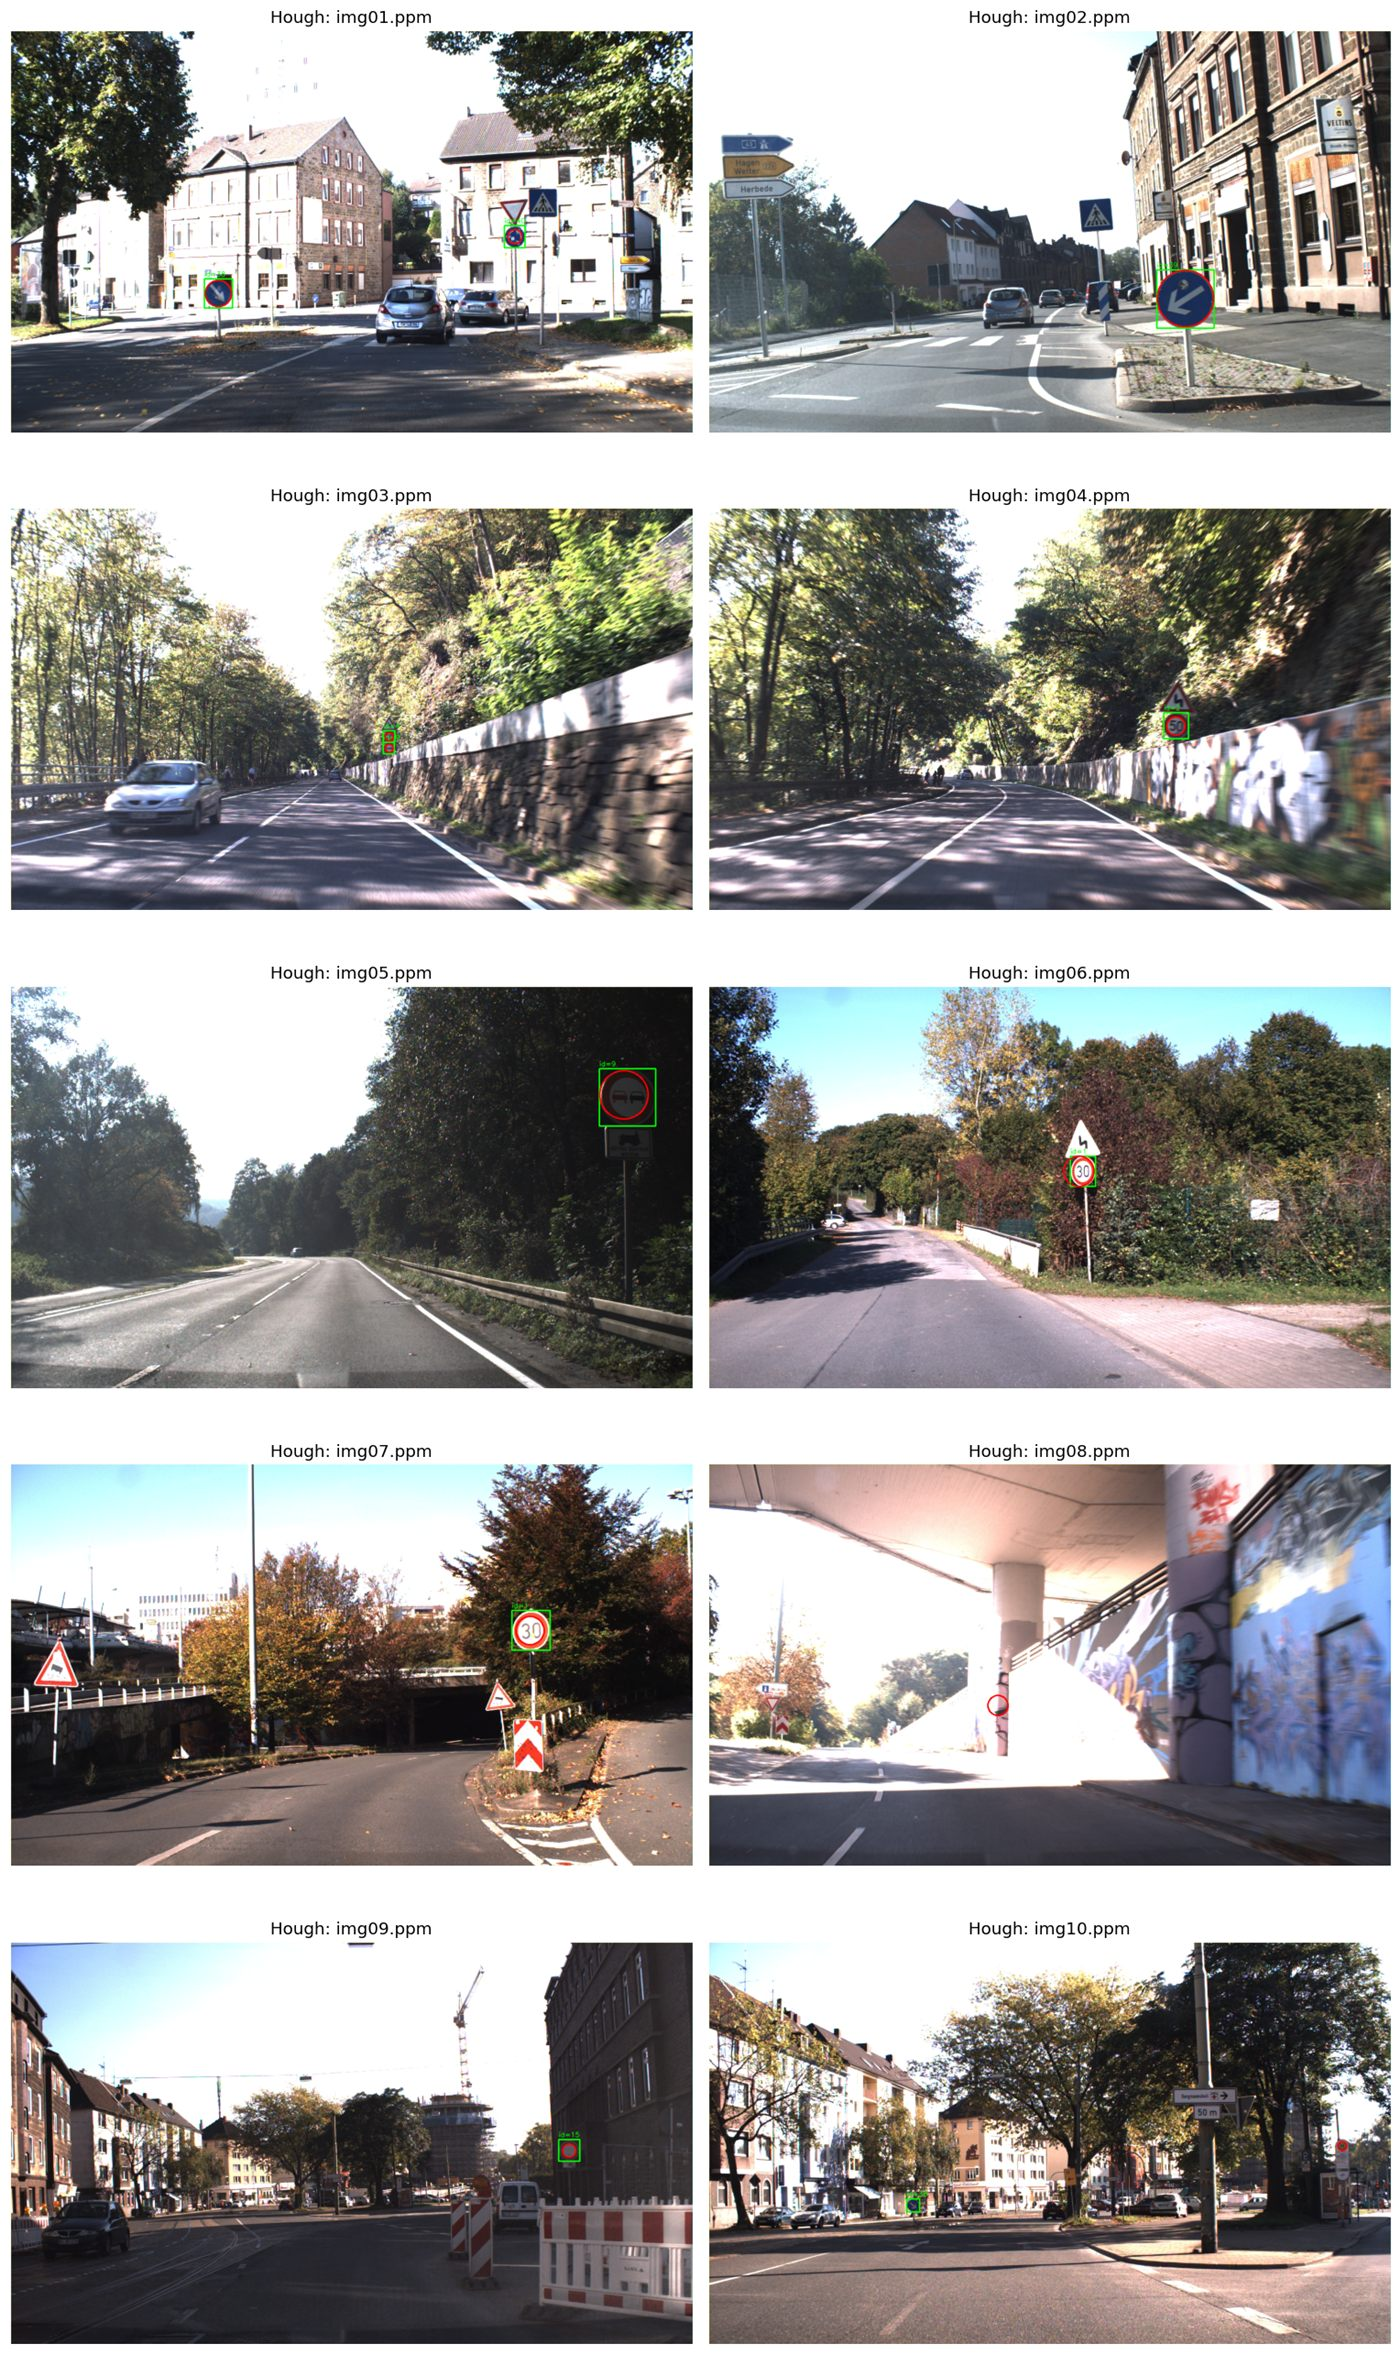

In [21]:
plot_detection_gallery(
    hough_detections,
    subset_image_names,
    title_prefix="Hough",
    pred_color=(255, 0, 0),
    ncols=2,
)

### Detection Gallery: RANSAC

The following gallery shows **10 example images** for RANSAC and makes it easier to interpret the very low precision values reported in the summary table.


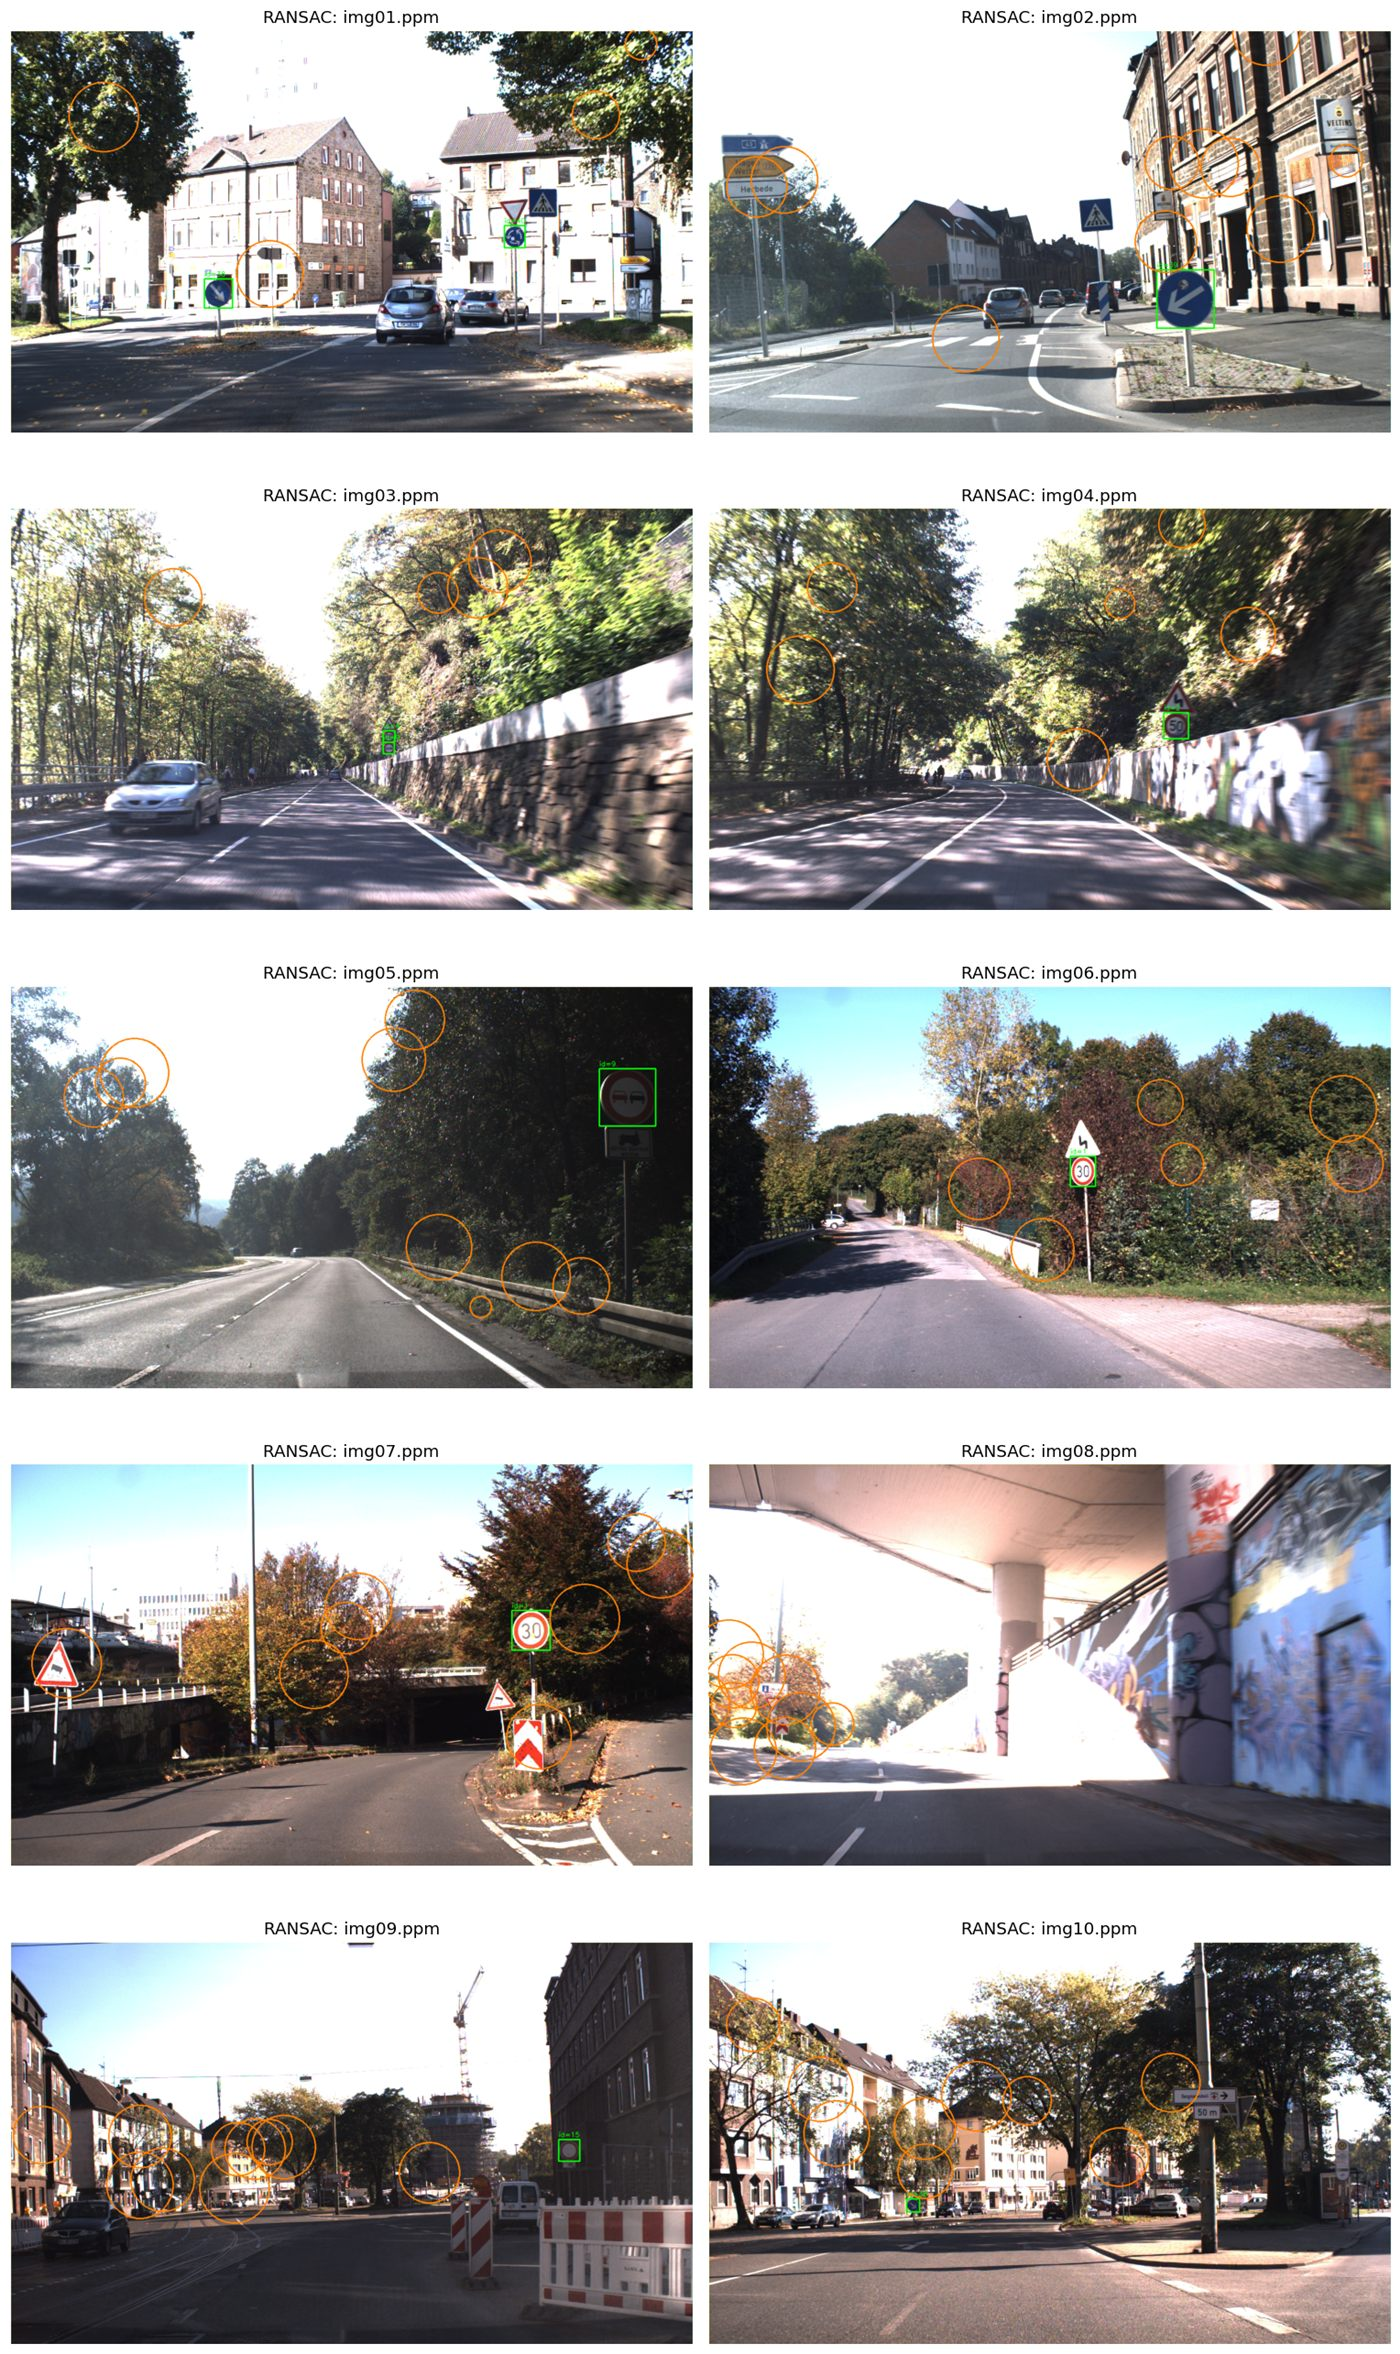

In [22]:

plot_detection_gallery(
    ransac_detections,
    subset_image_names,
    title_prefix="RANSAC",
    pred_color=(255, 128, 0),
    ncols=2,
)


### Precision-Recall Curves

The assignment asks for PR curves obtained by sweeping the vote or inlier threshold. The next cell performs that sweep for both detectors and plots the resulting precision-recall trade-off.

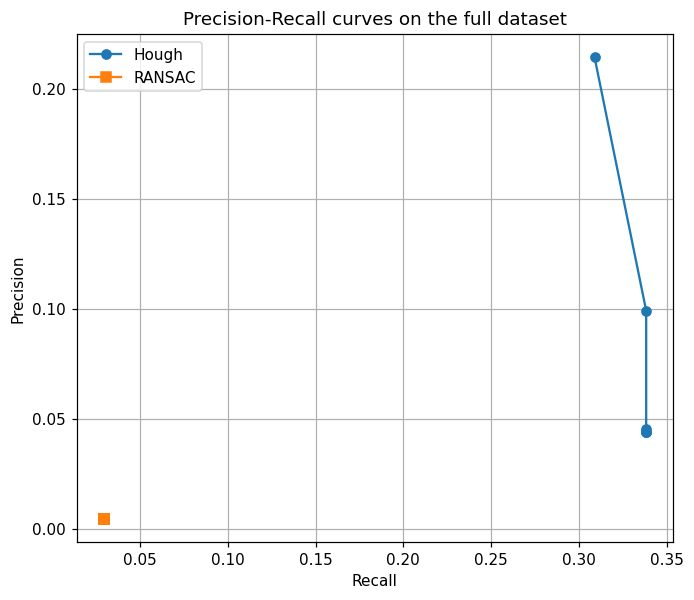

,threshold,precision,recall,f1
0,2,0.043977,0.338235,0.077834
1,4,0.043977,0.338235,0.077834
2,6,0.043977,0.338235,0.077834
3,8,0.045545,0.338235,0.080279
4,10,0.099138,0.338235,0.153333
5,12,0.214286,0.308824,0.253012


,threshold,precision,recall,f1
0,10,0.004545,0.029412,0.007874
1,20,0.004545,0.029412,0.007874
2,30,0.004545,0.029412,0.007874
3,40,0.004545,0.029412,0.007874
4,60,0.004545,0.029412,0.007874
5,80,0.004545,0.029412,0.007874


In [23]:
hough_pr = sweep_thresholds_for_pr(
    image_name_list=comparison_image_names,
    detector_name="hough",
    canny_cfg=best_canny_cfg,
    detector_cfg=default_hough_cfg,
    thresholds=[2, 4, 6, 8, 10, 12],
    iou_thr=0.5,
)

ransac_pr = sweep_thresholds_for_pr(
    image_name_list=comparison_image_names,
    detector_name="ransac",
    canny_cfg=best_canny_cfg,
    detector_cfg=default_ransac_cfg,
    thresholds=[10, 20, 30, 40, 60, 80],
    iou_thr=0.5,
)

plt.figure(figsize=(7, 6))
plt.plot(hough_pr["recall"], hough_pr["precision"], marker="o", label="Hough")
plt.plot(ransac_pr["recall"], ransac_pr["precision"], marker="s", label="RANSAC")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall curves on the full dataset")
plt.grid(True)
plt.legend()
plt.show()

display(hough_pr)
display(ransac_pr)

## PR-Curve Discussion

* The Hough threshold sweep behaves as expected. Increasing the vote threshold gradually removes weak accumulator peaks, which raises precision from about **0.044** at low thresholds to **0.214** at threshold **12**. Recall remains at **0.338** for thresholds **2** through **10**, and then drops slightly to **0.309** at threshold **12**. This indicates that Hough provides a meaningful precision-recall trade-off, with **threshold 12 giving the best balance within the tested range**.

* The RANSAC curve is almost completely flat: sweeping the minimum inlier threshold from **10** to **80** leaves the metrics essentially unchanged. This suggests that the main limitation is not threshold calibration alone. Instead, the current RANSAC procedure appears to generate many low-quality circle hypotheses, so changing the acceptance threshold has little practical effect. In this notebook, Hough is both more tunable and substantially more effective.

# 5. Multi-Scale Detection

Traffic signs appear at different apparent sizes because of viewing distance and perspective. To improve scale robustness, the detector is extended with a three-level image pyramid. At each scale, Canny edge detection and the circle detector are applied independently. The resulting circles are then mapped back to the original image coordinate system.

Because the same physical sign may be detected multiple times across neighbouring scales, an IoU-based Non-Maximum Suppression (NMS) step is applied after merging all detections. This section reports both:

1. the raw multi-scale detections before cross-scale NMS, and
2. the final detections after cross-scale NMS.

To make the effect of NMS explicit, I compare the methods both in terms of summary metrics and with a before/after precision–recall analysis obtained by threshold sweeping.


In [24]:
def build_image_pyramid(image_rgb, scales=(1.0, 0.75, 0.5)):
    pyramid = []
    for scale in scales:
        if scale == 1.0:
            resized = image_rgb.copy()
        else:
            resized = cv.resize(image_rgb, None, fx=scale, fy=scale, interpolation=cv.INTER_LINEAR)
        pyramid.append((scale, resized))
    return pyramid


def nms_circles(circles, iou_thr=0.3):
    circles = sorted(circles, key=lambda item: item[3], reverse=True)
    selected = []

    for candidate in circles:
        keep = True
        for chosen in selected:
            if circle_iou(candidate[:3], chosen[:3]) >= iou_thr:
                keep = False
                break
        if keep:
            selected.append(candidate)

    return selected


def multiscale_detect(image_rgb, method, canny_cfg, detector_cfg, scales=(1.0, 0.75, 0.5)):
    all_detections = []

    for scale, scaled_image in build_image_pyramid(image_rgb, scales=scales):
        if method == "hough":
            scaled_cfg = dict(detector_cfg)
            scaled_cfg["rmin"] = max(4, int(round(detector_cfg["rmin"] * scale)))
            scaled_cfg["rmax"] = max(scaled_cfg["rmin"] + 2, int(round(detector_cfg["rmax"] * scale)))
            scaled_cfg["min_dist"] = max(6, int(round(detector_cfg["min_dist"] * scale)))
            raw_edges, circles, _ = detect_hough_from_rgb(scaled_image, canny_cfg, scaled_cfg)
        else:
            scaled_cfg = dict(detector_cfg)
            scaled_cfg["rmin"] = max(4, int(round(detector_cfg["rmin"] * scale)))
            scaled_cfg["rmax"] = max(scaled_cfg["rmin"] + 2, int(round(detector_cfg["rmax"] * scale)))
            raw_edges, circles = detect_ransac_from_rgb(scaled_image, canny_cfg, scaled_cfg)

        for xc, yc, radius, score in circles:
            all_detections.append((xc / scale, yc / scale, radius / scale, score))

    before_nms = all_detections
    after_nms = nms_circles(all_detections, iou_thr=0.3)
    return before_nms, after_nms


def evaluate_multiscale_on_images(image_name_list, method, canny_cfg, detector_cfg, scales=(1.0, 0.75, 0.5), iou_thr=0.5):
    rows = []
    for stage_name in ["before_nms", "after_nms"]:
        total_tp = total_fp = total_fn = 0
        matched_ious = []
        runtimes = []

        for image_name in image_name_list:
            image_rgb = read_rgb(image_name)
            gt_rows = get_image_gt(image_name, circular_only=True)
            gt_boxes = [gt_row_to_box(row) for _, row in gt_rows.iterrows()]

            t0 = time.perf_counter()
            before_nms, after_nms = multiscale_detect(
                image_rgb=image_rgb,
                method=method,
                canny_cfg=canny_cfg,
                detector_cfg=detector_cfg,
                scales=scales,
            )
            elapsed = time.perf_counter() - t0
            runtimes.append(elapsed)

            pred_circles = before_nms if stage_name == "before_nms" else after_nms
            matches, tp, fp, fn = greedy_match_detections(pred_circles, gt_boxes, iou_thr=iou_thr)
            total_tp += tp
            total_fp += fp
            total_fn += fn
            matched_ious.extend([match[2] for match in matches])

        precision, recall, f1 = compute_prf(total_tp, total_fp, total_fn)
        rows.append(
            {
                "stage": stage_name,
                "precision": precision,
                "recall": recall,
                "f1": f1,
                "mean_matched_iou": float(np.mean(matched_ious)) if matched_ious else 0.0,
                "avg_runtime_sec": float(np.mean(runtimes)) if runtimes else 0.0,
            }
        )

    return pd.DataFrame(rows)


### Per-Scale Detection Example

Before merging detections across scales, it is useful to inspect the detector output at each pyramid level separately. The following example shows the detections obtained at each scale on the same image. This makes it easier to see which signs are already visible at the original resolution and which ones become easier to detect at smaller pyramid levels.

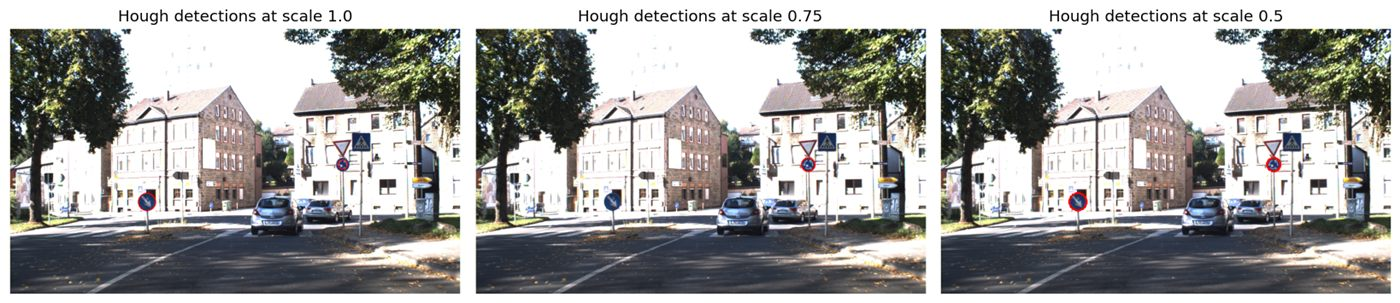

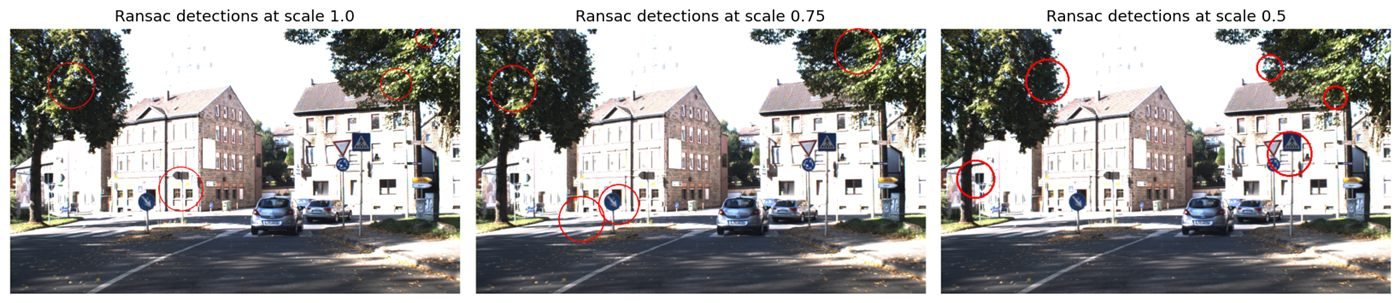

In [30]:
def show_per_scale_detections(image_rgb, method, canny_cfg, detector_cfg, scales=(1.0, 0.75, 0.5)):
    fig, axes = plt.subplots(1, len(scales), figsize=(5 * len(scales), 5))
    if len(scales) == 1:
        axes = [axes]

    for ax, scale in zip(axes, scales):
        if scale == 1.0:
            scaled_image = image_rgb.copy()
        else:
            scaled_image = cv.resize(
                image_rgb, None, fx=scale, fy=scale, interpolation=cv.INTER_LINEAR
            )

        if method == "hough":
            scaled_cfg = dict(detector_cfg)
            scaled_cfg["rmin"] = max(4, int(round(detector_cfg["rmin"] * scale)))
            scaled_cfg["rmax"] = max(scaled_cfg["rmin"] + 2, int(round(detector_cfg["rmax"] * scale)))
            scaled_cfg["min_dist"] = max(6, int(round(detector_cfg["min_dist"] * scale)))
            _, circles, _ = detect_hough_from_rgb(scaled_image, canny_cfg, scaled_cfg)
        else:
            scaled_cfg = dict(detector_cfg)
            scaled_cfg["rmin"] = max(4, int(round(detector_cfg["rmin"] * scale)))
            scaled_cfg["rmax"] = max(scaled_cfg["rmin"] + 2, int(round(detector_cfg["rmax"] * scale)))
            _, circles = detect_ransac_from_rgb(scaled_image, canny_cfg, scaled_cfg)

        overlay = scaled_image.copy()
        for xc, yc, radius, score in circles:
            cv.circle(
                overlay,
                (int(round(xc)), int(round(yc))),
                int(round(radius)),
                (255, 0, 0),
                2,
            )

        ax.imshow(overlay)
        ax.set_title(f"{method.capitalize()} detections at scale {scale}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_per_scale_detections(
    sample_image,
    method="hough",
    canny_cfg=best_canny_cfg,
    detector_cfg=default_hough_cfg,
)

show_per_scale_detections(
    sample_image,
    method="ransac",
    canny_cfg=best_canny_cfg,
    detector_cfg=default_ransac_cfg,
)

Multi-scale detections before NMS: 5
Multi-scale detections after  NMS: 2


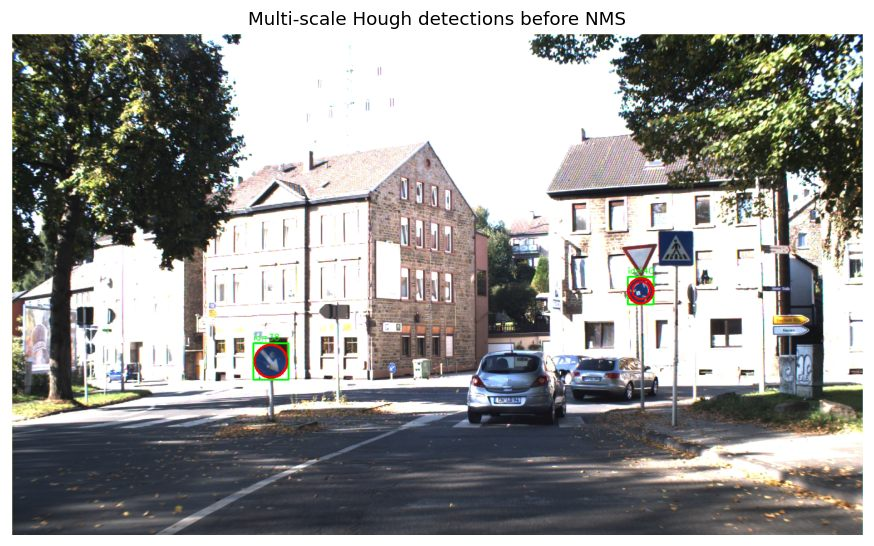

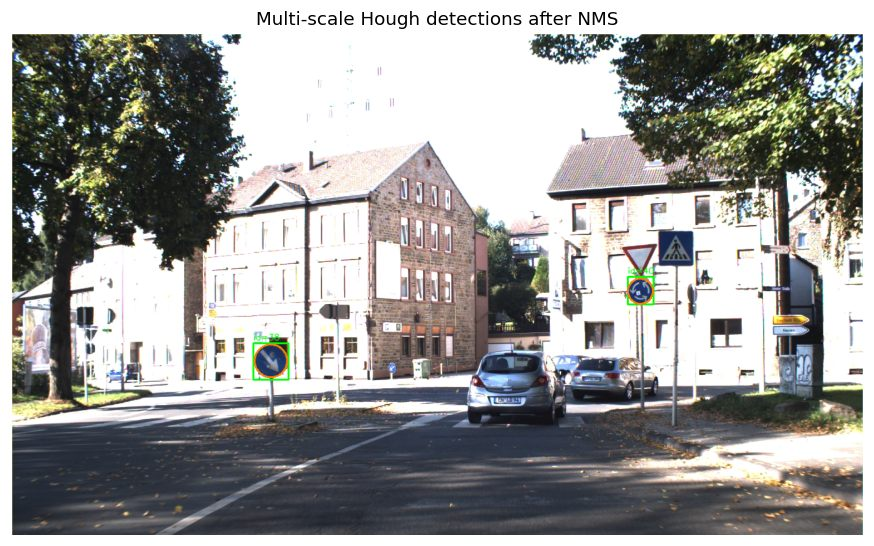

In [31]:
SCALES = (1.0, 0.75, 0.5)

ms_before, ms_after = multiscale_detect(
    sample_image,
    method="hough",
    canny_cfg=best_canny_cfg,
    detector_cfg=default_hough_cfg,
    scales=SCALES,
)

print("Multi-scale detections before NMS:", len(ms_before))
print("Multi-scale detections after  NMS:", len(ms_after))

overlay_gt_and_predictions(
    sample_image,
    sample_image_name,
    ms_before,
    pred_color=(255, 0, 0),
    title="Multi-scale Hough detections before NMS",
)

overlay_gt_and_predictions(
    sample_image,
    sample_image_name,
    ms_after,
    pred_color=(255, 128, 0),
    title="Multi-scale Hough detections after NMS",
)


Before NMS, the multi-scale Hough detector returns **5 circles**, even though only **2 true circular signs** are present. After NMS, this is reduced to **2 detections**, which matches the actual number of target signs in the scene. This confirms that cross-scale NMS successfully removes duplicate detections while preserving the true positives.

## Multi-Scale Summary : Hough - RANSAC

In [26]:
multiscale_hough_eval = evaluate_multiscale_on_images(
    image_name_list=image_names,
    method="hough",
    canny_cfg=best_canny_cfg,
    detector_cfg=default_hough_cfg,
    scales=SCALES,
    iou_thr=0.5,
)

multiscale_ransac_eval = evaluate_multiscale_on_images(
    image_name_list=image_names,
    method="ransac",
    canny_cfg=best_canny_cfg,
    detector_cfg=default_ransac_cfg,
    scales=SCALES,
    iou_thr=0.5,
)

print("Hough multi-scale summary")
display(multiscale_hough_eval)

print("RANSAC multi-scale summary")
display(multiscale_ransac_eval)


Hough multi-scale summary


,stage,precision,recall,f1,mean_matched_iou,avg_runtime_sec
0,before_nms,0.164706,0.411765,0.235294,0.658466,4.829901
1,after_nms,0.282051,0.323529,0.301370,0.650975,4.840228


RANSAC multi-scale summary


,stage,precision,recall,f1,mean_matched_iou,avg_runtime_sec
0,before_nms,0.003943,0.073529,0.007485,0.662069,0.320336
1,after_nms,0.004920,0.058824,0.009081,0.681133,0.319938


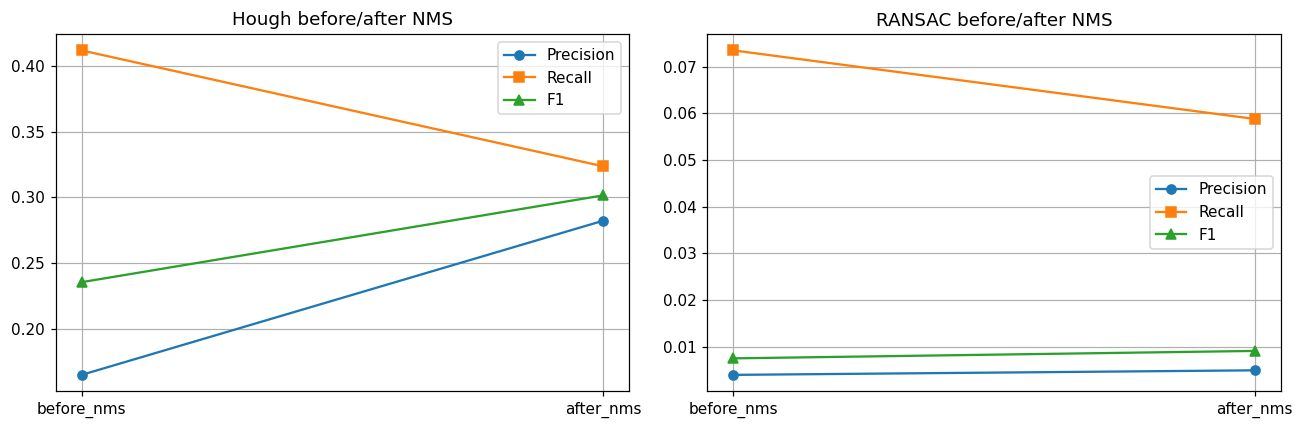

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(multiscale_hough_eval["stage"], multiscale_hough_eval["precision"], marker="o", label="Precision")
axes[0].plot(multiscale_hough_eval["stage"], multiscale_hough_eval["recall"], marker="s", label="Recall")
axes[0].plot(multiscale_hough_eval["stage"], multiscale_hough_eval["f1"], marker="^", label="F1")
axes[0].set_title("Hough before/after NMS")
axes[0].grid(True)
axes[0].legend()

axes[1].plot(multiscale_ransac_eval["stage"], multiscale_ransac_eval["precision"], marker="o", label="Precision")
axes[1].plot(multiscale_ransac_eval["stage"], multiscale_ransac_eval["recall"], marker="s", label="Recall")
axes[1].plot(multiscale_ransac_eval["stage"], multiscale_ransac_eval["f1"], marker="^", label="F1")
axes[1].set_title("RANSAC before/after NMS")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()


## Multi-Scale Discussion

* Multi-scale detection can improve recall because some small or weak signs become easier to detect at another pyramid level. However, it also introduces duplicate detections across scales, which reduces precision before NMS.

* This effect is clear for **Hough**. Before NMS, recall is higher (**0.4118**), but precision is low (**0.1647**) due to duplicate detections. After NMS, precision increases to **0.2821** and **F1** improves from **0.2353** to **0.3014**, while recall decreases to **0.3235**. This shows that NMS is an important post-processing step in the multi-scale Hough setting.

* For **RANSAC**, the effect is much weaker. NMS gives only a very small improvement in **F1** (**0.0075 -> 0.0091**), which suggests that the main limitation is not duplicate detections alone, but also unstable circle hypotheses.

Overall, multi-scale processing is useful for generating additional candidates, while **IoU-based NMS** is necessary to remove duplicates. However, the final multi-scale Hough result (**F1 = 0.3014**)  remains slightly below the best **single-scale Hough** result (**F1 = 0.3030**).

# 6.  Failure Analysis and Discussions

In this section, **6 representative failure cases** are analysed in order to highlight the limitations of both detectors. The selected examples include **3 Hough** and **3 RANSAC** results, covering both **false-positive-heavy** and **false-negative-heavy** behaviour. The first cell summarises these cases numerically, and the following cell visualises them directly on the original images.



In [28]:
selected_failures = [
   ("Hough", "img14.ppm"),
     ("Hough", "img17.ppm"),
     ("Hough", "img36.ppm"),
    ("RANSAC", "img24.ppm"),
    ("RANSAC", "img28.ppm"),
    ("RANSAC", "img42.ppm"),
]

failure_rows = []
for method, image_name in selected_failures:
    if method == "Hough":
        row = hough_per_image_df[hough_per_image_df["image_name"] == image_name].copy()
    else:
        row = ransac_per_image_df[ransac_per_image_df["image_name"] == image_name].copy()

    if not row.empty:
        row["method"] = method
        failure_rows.append(row)

if failure_rows:
    failure_cases_df = pd.concat(failure_rows, ignore_index=True)
    display(failure_cases_df[["method", "image_name", "tp", "fp", "fn", "precision", "recall", "f1"]])


,method,image_name,tp,fp,fn,precision,recall,f1
0,Hough,img14.ppm,1,8,0,0.111111,1.000000,0.2
1,Hough,img17.ppm,1,0,2,1.000000,0.333333,0.5
2,Hough,img36.ppm,0,2,4,0.000000,0.000000,0.0
3,RANSAC,img24.ppm,0,10,2,0.000000,0.000000,0.0
4,RANSAC,img28.ppm,0,10,2,0.000000,0.000000,0.0
5,RANSAC,img42.ppm,0,10,2,0.000000,0.000000,0.0


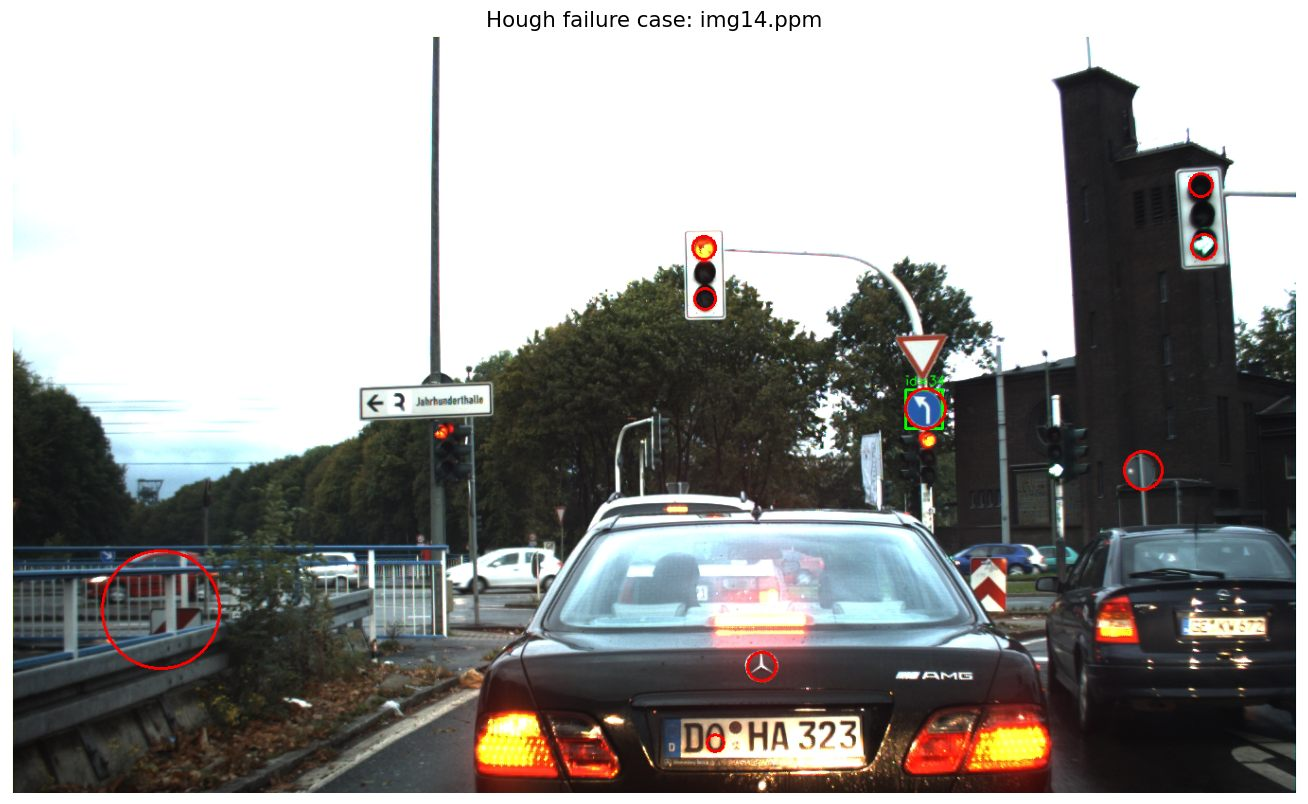

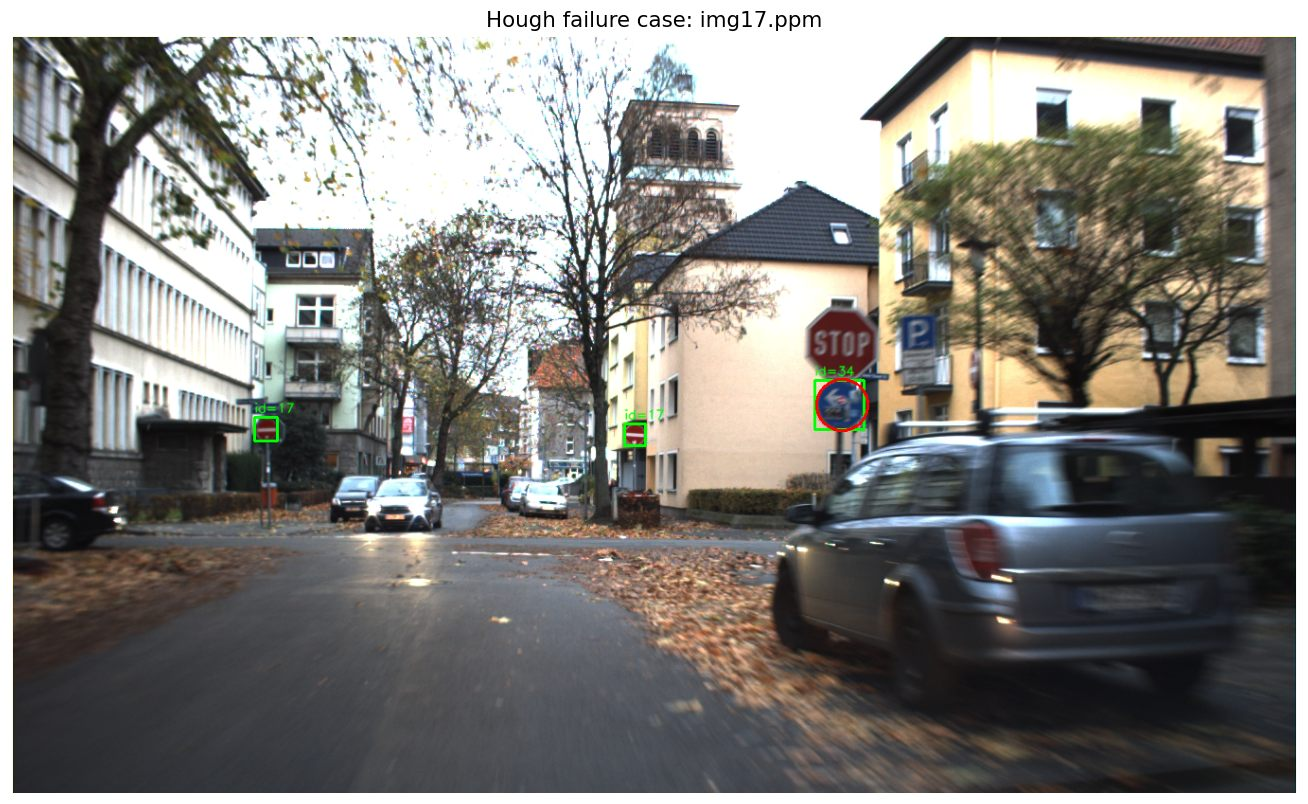

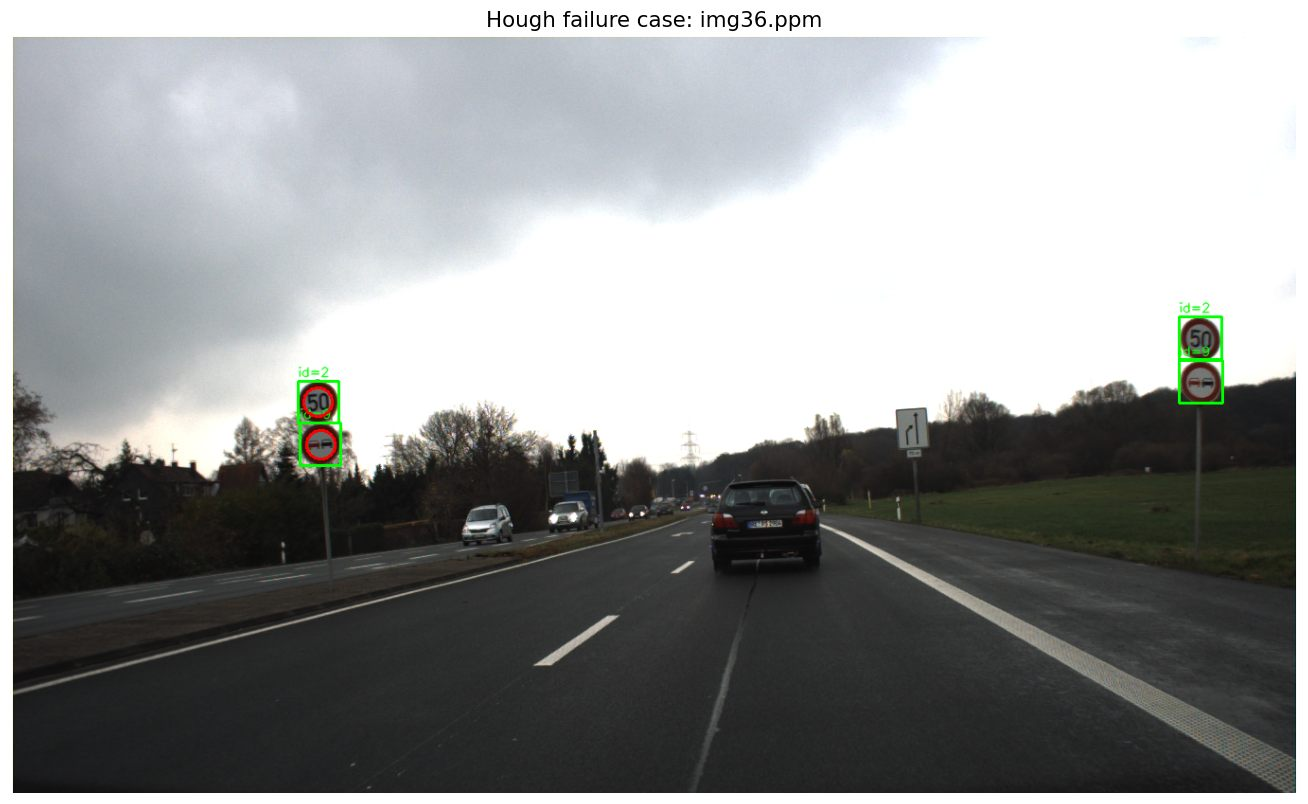

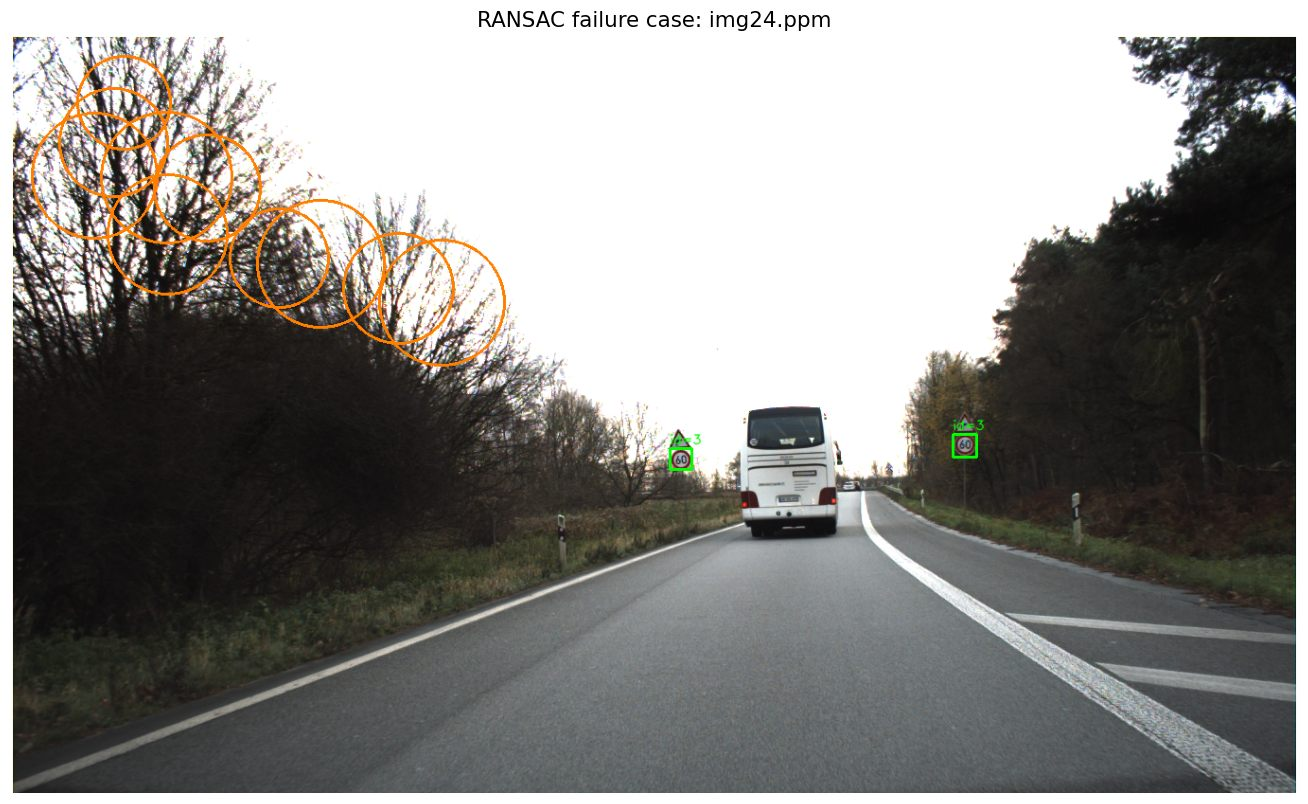

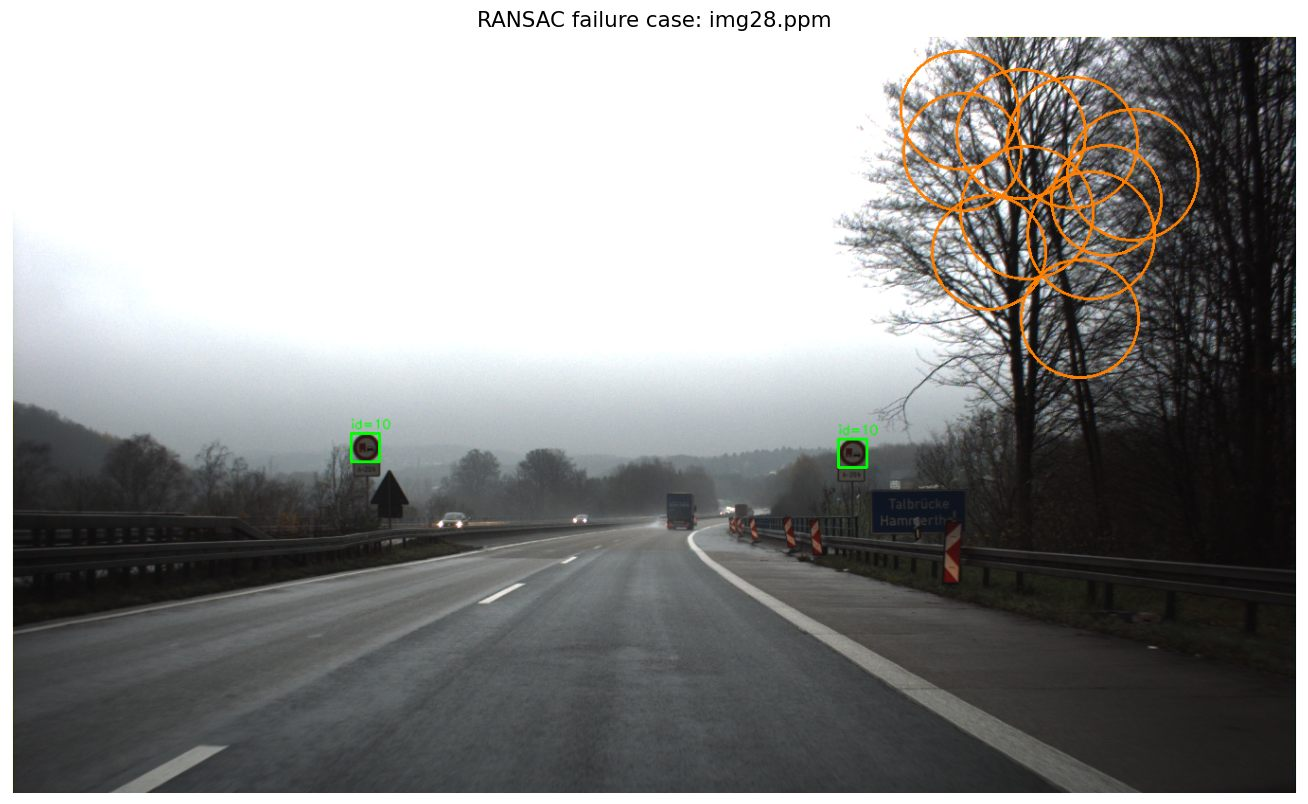

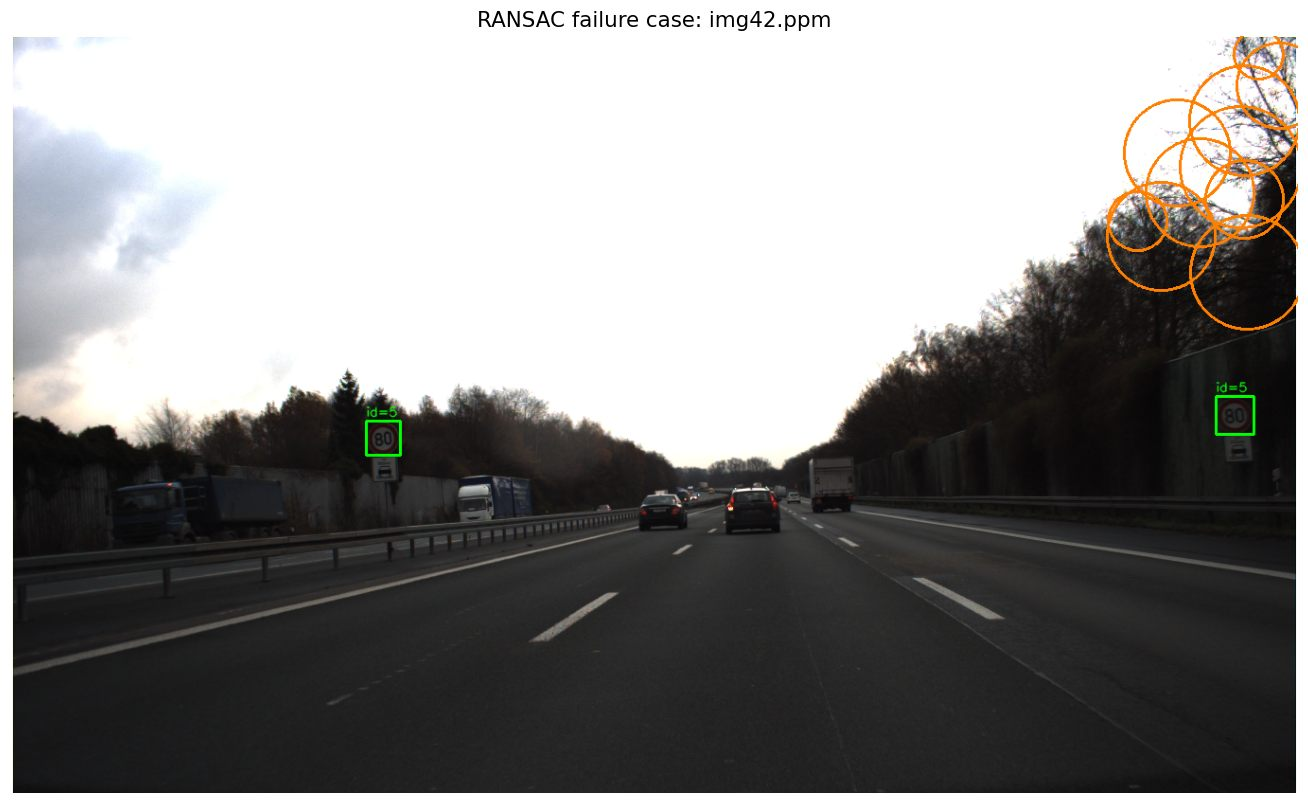

In [29]:
for _, row in failure_cases_df.iterrows():
    method = row["method"]
    image_name = row["image_name"]

    if method == "Hough":
        image_rgb = hough_detections[image_name]["image_rgb"]
        circles = hough_detections[image_name]["circles"]
        pred_color = (255, 0, 0)
    else:
        image_rgb = ransac_detections[image_name]["image_rgb"]
        circles = ransac_detections[image_name]["circles"]
        pred_color = (255, 128, 0)

    overlay = draw_ground_truth(image_rgb, image_name, circular_only=True)
    for xc, yc, radius, score in circles:
        cv.circle(
            overlay,
            (int(round(xc)), int(round(yc))),
            int(round(radius)),
            pred_color,
            2
        )

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(overlay)
    ax.set_title(f"{method} failure case: {image_name}", fontsize=14)
    ax.axis("off")

    plt.tight_layout()
    plt.show()

## Failure Analysis

These six examples illustrate the dominant failure modes of the two detectors. Across both methods, the main sources of error are background clutter, small object scale, weak or fragmented sign boundaries, and challenging illumination conditions.

- **Hough, `img14.ppm`**: The true sign is detected, but the method also produces several false positives on traffic lights, the car emblem, and other round structures. This is a **false-positive-dominated** case caused by strong circular edges in the scene, which generate additional peaks in the accumulator. A possible improvement is to use a higher vote threshold together with colour-based or region-based verification.

- **Hough, `img17.ppm`**: Only the larger sign is detected, while the two smaller distant signs are missed. This is mainly a **false-negative** case caused by small object scale, weak edge support, and scene clutter. A possible improvement is to strengthen the multi-scale search and reduce the minimum searched radius.

- **Hough, `img36.ppm`**: The detector misses the visible circular signs in this scene. The main difficulty is that the signs are small and appear under uneven illumination, with a very bright background and a darker foreground, so their circular boundaries are weak. A possible improvement is to apply contrast enhancement before Canny and make the fine-scale search more sensitive.

- **RANSAC, `img24.ppm`**: Most detections occur in the tree area, while the real roadside signs are missed. This is a **background-clutter failure**: branches against the bright sky create many curved edge fragments that support incorrect circle hypotheses. A possible improvement is to apply stronger pre-filtering or a stricter post-verification step after fitting.

- **RANSAC, `img28.ppm`**: The detector again fits many false circles to background structures and misses both real signs. Here the true signs are small and low-contrast, so they do not provide stable inlier support, whereas cluttered edges produce many accidental circle fits. A possible improvement is to combine multi-scale detection with stricter acceptance criteria for fitted circles.

- **RANSAC, `img42.ppm`**: False detections are again concentrated in the cluttered background, while the real signs are missed. This shows that the current RANSAC stage is overly sensitive to irregular natural edges and does not sufficiently verify whether a fitted circle corresponds to a real traffic sign. A possible improvement is to enforce stronger circle-quality checks, such as boundary completeness or colour-based validation.

Overall, **Hough Transform** is the more useful detector in this notebook. Although it still produces false positives, it recovers real traffic signs more consistently and offers a more controllable precision–recall trade-off. **RANSAC** is faster, but in its current form it is much more sensitive to clutter and frequently fits circles to non-sign structures. Among the tested pipelines, the evidence supports **Hough** as the more reliable detector overall. In the multi-scale setting, **IoU-based NMS** is clearly beneficial for reducing duplicate detections, but it does **not** outperform the best single-scale Hough result on this dataset.

